In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, MinMaxScaler

In [2]:
df = pd.read_excel('CIA 1.xlsx')

In [3]:
df.head(10)

,Listing_ID,Seller_ID,Product_Name,Brand,Category,Condition,Storage_GB,RAM_GB,Purchase_Year,Warranty_Status,...,Views,Wishlist_Count,Negotiation_Level,Sale_Status,Final_Price_INR,Customer_Type,Advertisement_Text,Manufacture_Code,Age,Favorite_Color
0,L0001,S113,Nord,HP,Tablet,Excellent,1024.0,12,2018,Active,...,8.0,20.0,Low,Sold,8753.0,Student,Fast delivery | Free charger | Slight scratches,MFG-4257,8,Yellow
1,L0002,S100,iPhone,HP,Laptop,Average,256.0,6,2025,Active,...,NaN,44.0,Low,Sold,73034.0,Student,Fast delivery | Free charger | Slight scratches,MFG-6881,1,Green
2,L0003,S148,Galaxy S,Dell,Laptop,Average,1024.0,6,2026,Active,...,NaN,27.0,High,Sold,52745.0,Student,Fast delivery | Free charger | Slight scratches,MFG-4814,0,Red
3,L0004,S145,iPhone,HP,Laptop,Excellent,1024.0,32,2023,Active,...,44.0,7.0,High,Sold,34795.0,Reseller,Fast delivery | Free charger | Slight scratches,MFG-7216,3,Green
4,L0005,S129,Galaxy S,Lenovo,Laptop,Poor,256.0,4,2025,Active,...,73.0,19.0,High,Unsold,33644.0,Reseller,Fast delivery | Free charger | Slight scratches,MFG-7482,1,Yellow
5,L0006,S133,Nord,Dell,Laptop,Poor,256.0,6,2024,Active,...,221.0,21.0,Medium,Sold,24755.0,Student,Fast delivery | Free charger | Slight scratches,MFG-3504,2,Yellow
6,L0007,S159,Mi Pad,OnePlus,Tablet,Excellent,64.0,32,2019,Expired,...,327.0,61.0,Medium,Sold,37903.0,Reseller,Fast delivery | Free charger | Slight scratches,MFG-3591,7,Black
7,L0008,S113,Nord,OnePlus,Tablet,Good,128.0,8,2017,Active,...,3.0,6.0,High,Sold,970.0,Business,Fast delivery | Free charger | Slight scratches,MFG-9005,9,Red
8,L0009,S107,iPhone,Dell,Phone,Excellent,512.0,4,2018,Active,...,398.0,16.0,High,Unsold,72322.0,Professional,Fast delivery | Free charger | Slight scratches,MFG-5342,8,White
9,L0010,S125,Nord,OnePlus,Laptop,Average,512.0,16,2026,Expired,...,57.0,20.0,Low,Sold,34184.0,Business,Fast delivery | Free charger | Slight scratches,MFG-1344,0,White


In [4]:
df.tail(10)

,Listing_ID,Seller_ID,Product_Name,Brand,Category,Condition,Storage_GB,RAM_GB,Purchase_Year,Warranty_Status,...,Views,Wishlist_Count,Negotiation_Level,Sale_Status,Final_Price_INR,Customer_Type,Advertisement_Text,Manufacture_Code,Age,Favorite_Color
290,L0291,S146,Galaxy S,Apple,Laptop,Poor,128.0,12,2024,Active,...,255.0,10.0,Medium,Pending,1214.0,Student,Fast delivery | Free charger | Slight scratches,MFG-4054,2,Blue
291,L0292,S167,ThinkPad,OnePlus,Laptop,Poor,128.0,4,2025,Expired,...,266.0,3.0,Medium,Unsold,13688.0,Professional,Fast delivery | Free charger | Slight scratches,MFG-9212,1,Green
292,L0293,S103,Mi Pad,OnePlus,Phone,Good,256.0,12,2017,Active,...,18.0,47.0,High,Unsold,64545.0,Professional,Fast delivery | Free charger | Slight scratches,MFG-7837,9,Blue
293,L0294,S157,Mi Pad,Samsung,Phone,Good,1024.0,16,2026,Active,...,16.0,36.0,Medium,Pending,NaN,Professional,Fast delivery | Free charger | Slight scratches,MFG-8046,0,Blue
294,L0295,S115,iPhone,OnePlus,Phone,Excellent,256.0,12,2026,Expired,...,16.0,30.0,Medium,Pending,17883.0,Professional,Fast delivery | Free charger | Slight scratches,MFG-4079,0,Red
295,L0296,S177,Mi Pad,Dell,Phone,Good,128.0,32,2019,Active,...,142.0,20.0,Low,Pending,NaN,Professional,Fast delivery | Free charger | Slight scratches,MFG-9230,7,White
296,L0297,S120,iPhone,Samsung,Phone,Poor,64.0,8,2024,Expired,...,13.0,5.0,High,Pending,71760.0,Professional,Fast delivery | Free charger | Slight scratches,MFG-2083,2,Blue
297,L0298,S154,Inspiron,Lenovo,Phone,Poor,256.0,12,2024,Active,...,18.0,21.0,Low,Unsold,54282.0,Student,Fast delivery | Free charger | Slight scratches,MFG-5025,2,White
298,L0299,S180,Galaxy S,Samsung,Laptop,Poor,512.0,8,2025,Expired,...,10.0,10.0,Low,Unsold,77462.0,Student,Fast delivery | Free charger | Slight scratches,MFG-9470,1,Blue
299,L0300,S174,Nord,Dell,Phone,Poor,512.0,8,2024,Expired,...,141.0,34.0,Low,Unsold,54252.0,Professional,Fast delivery | Free charger | Slight scratches,MFG-8449,2,Red


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 27 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Listing_ID          300 non-null    object 
 1   Seller_ID           300 non-null    object 
 2   Product_Name        300 non-null    object 
 3   Brand               300 non-null    object 
 4   Category            300 non-null    object 
 5   Condition           300 non-null    object 
 6   Storage_GB          290 non-null    float64
 7   RAM_GB              300 non-null    int64  
 8   Purchase_Year       300 non-null    int64  
 9   Warranty_Status     300 non-null    object 
 10  City                300 non-null    object 
 11  Seller_Rating       292 non-null    float64
 12  Asking_Price_INR    291 non-null    float64
 13  Original_Price_INR  300 non-null    int64  
 14  Age_Years           300 non-null    int64  
 15  Battery_Health      290 non-null    float64
 16  Days_Lis

In [6]:
df.describe()

,Storage_GB,RAM_GB,Purchase_Year,Seller_Rating,Asking_Price_INR,Original_Price_INR,Age_Years,Battery_Health,Days_Listed,Views,Wishlist_Count,Final_Price_INR,Age
count,290.000000,300.000000,300.000000,292.000000,291.000000,300.000000,300.000000,290.000000,300.000000,293.000000,292.000000,292.00000,300.000000
mean,419.310345,13.386667,2021.786667,4.165068,34114.800687,84234.523333,4.213333,79.434483,30.236667,182.518771,29.267123,32129.90411,4.213333
std,348.061752,9.718298,2.868551,0.427507,31059.860782,39170.317484,2.868551,13.221464,5.395463,310.796167,19.956754,31496.46787,2.868551
min,64.000000,4.000000,2017.000000,2.700000,3000.000000,15314.000000,0.000000,20.000000,13.000000,1.000000,1.000000,-1804.00000,0.000000
25%,128.000000,6.000000,2019.000000,3.900000,13088.500000,51999.750000,2.000000,73.000000,27.000000,42.000000,15.000000,10833.00000,2.000000
50%,256.000000,12.000000,2022.000000,4.100000,27997.000000,84602.000000,4.000000,81.000000,30.000000,115.000000,25.500000,25637.00000,4.000000
75%,512.000000,16.000000,2024.000000,4.500000,47230.000000,118729.000000,7.000000,87.000000,34.000000,220.000000,39.000000,46526.75000,7.000000
max,1024.000000,32.000000,2026.000000,5.000000,301430.000000,149932.000000,9.000000,100.000000,46.000000,2500.000000,116.000000,297059.00000,9.000000


In [7]:
print("Random sample:")
display(df.sample(5))

Random sample:


,Listing_ID,Seller_ID,Product_Name,Brand,Category,Condition,Storage_GB,RAM_GB,Purchase_Year,Warranty_Status,...,Views,Wishlist_Count,Negotiation_Level,Sale_Status,Final_Price_INR,Customer_Type,Advertisement_Text,Manufacture_Code,Age,Favorite_Color
115,L0116,S147,Mi Pad,Samsung,Phone,Good,512.0,6,2025,Expired,...,217.0,41.0,High,Unsold,35129.0,Reseller,Fast delivery | Free charger | Slight scratches,MFG-9806,1,Yellow
241,L0242,S120,iPhone,HP,Tablet,Excellent,1024.0,6,2019,Active,...,2.0,37.0,Medium,Sold,79447.0,Reseller,Fast delivery | Free charger | Slight scratches,MFG-1305,7,Yellow
39,L0040,S162,Galaxy S,Lenovo,Phone,Average,512.0,12,2017,Expired,...,6.0,23.0,Low,Sold,32247.0,Reseller,Fast delivery | Free charger | Slight scratches,MFG-2869,9,Red
257,L0258,S163,Inspiron,Samsung,Laptop,Average,256.0,12,2020,Expired,...,1.0,48.0,Low,Pending,37173.0,Professional,Fast delivery | Free charger | Slight scratches,MFG-2636,6,Yellow
258,L0259,S119,Inspiron,Lenovo,Phone,Good,512.0,12,2021,Active,...,208.0,26.0,High,Pending,46427.0,Reseller,Fast delivery | Free charger | Slight scratches,MFG-5915,5,Green


In [8]:
print("Dataset Shape:")
print(df.shape)

print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Dataset Shape:
(300, 27)
Number of Rows: 300
Number of Columns: 27


In [10]:
print("Column Names:")
print(df.columns.tolist())

Column Names:
['Listing_ID', 'Seller_ID', 'Product_Name', 'Brand', 'Category', 'Condition', 'Storage_GB', 'RAM_GB', 'Purchase_Year', 'Warranty_Status', 'City', 'Seller_Rating', 'Asking_Price_INR', 'Original_Price_INR', 'Age_Years', 'Battery_Health', 'Days_Listed', 'Views', 'Wishlist_Count', 'Negotiation_Level', 'Sale_Status', 'Final_Price_INR', 'Customer_Type', 'Advertisement_Text', 'Manufacture_Code', 'Age', 'Favorite_Color']


In [11]:
print("Data Types:")
display(df.dtypes)

Data Types:


,0
Listing_ID,object
Seller_ID,object
Product_Name,object
Brand,object
Category,object
Condition,object
Storage_GB,float64
RAM_GB,int64
Purchase_Year,int64
Warranty_Status,object


In [13]:
print("Missing values in each column:")
display(df.isnull().sum())

Missing values in each column:


,0
Listing_ID,0
Seller_ID,0
Product_Name,0
Brand,0
Category,0
Condition,0
Storage_GB,10
RAM_GB,0
Purchase_Year,0
Warranty_Status,0


In [14]:
numerical_columns = df.select_dtypes(include=['int64', 'float64']).columns
categorical_columns = df.select_dtypes(include=['object']).columns

print("Numerical Columns:")
print(list(numerical_columns))

print("\nCategorical Columns:")
print(list(categorical_columns))

Numerical Columns:
['Storage_GB', 'RAM_GB', 'Purchase_Year', 'Seller_Rating', 'Asking_Price_INR', 'Original_Price_INR', 'Age_Years', 'Battery_Health', 'Days_Listed', 'Views', 'Wishlist_Count', 'Final_Price_INR', 'Age']

Categorical Columns:
['Listing_ID', 'Seller_ID', 'Product_Name', 'Brand', 'Category', 'Condition', 'Warranty_Status', 'City', 'Negotiation_Level', 'Sale_Status', 'Customer_Type', 'Advertisement_Text', 'Manufacture_Code', 'Favorite_Color']


In [15]:
for column in numerical_columns:
    if df[column].isnull().sum() > 0:
        df[column] = df[column].fillna(df[column].median())

In [16]:
for column in categorical_columns:
    if df[column].isnull().sum() > 0:
        df[column] = df[column].fillna(df[column].mode()[0])

In [17]:
display(df.isnull().sum())

,0
Listing_ID,0
Seller_ID,0
Product_Name,0
Brand,0
Category,0
Condition,0
Storage_GB,0
RAM_GB,0
Purchase_Year,0
Warranty_Status,0


In [18]:
print("Total missing values:", df.isnull().sum().sum())

Total missing values: 0


In [19]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [20]:
df = df.drop_duplicates()

print("Shape after removing duplicates:")
print(df.shape)

Shape after removing duplicates:
(300, 27)


In [21]:
print("Remaining duplicate rows:", df.duplicated().sum())

Remaining duplicate rows: 0


In [22]:
numeric_columns = [
    'Storage_GB',
    'RAM_GB',
    'Purchase_Year',
    'Seller_Rating',
    'Asking_Price_INR',
    'Original_Price_INR',
    'Age_Years',
    'Battery_Health',
    'Days_Listed',
    'Views',
    'Wishlist_Count',
    'Final_Price_INR',
    'Age'
]

In [23]:
for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors='coerce')

In [24]:
display(df[numeric_columns].dtypes)


,0
Storage_GB,float64
RAM_GB,int64
Purchase_Year,int64
Seller_Rating,float64
Asking_Price_INR,float64
Original_Price_INR,int64
Age_Years,int64
Battery_Health,float64
Days_Listed,int64
Views,float64


In [25]:
df['Listing_ID'] = df['Listing_ID'].astype(str)
df['Seller_ID'] = df['Seller_ID'].astype(str)

In [26]:
categorical_columns = [
    'Product_Name',
    'Brand',
    'Category',
    'Condition',
    'Warranty_Status',
    'City',
    'Negotiation_Level',
    'Sale_Status',
    'Customer_Type',
    'Advertisement_Text',
    'Manufacture_Code',
    'Favorite_Color'
]

for column in categorical_columns:
    df[column] = df[column].astype(str)

In [27]:
print("Final data types:")
display(df.dtypes)

Final data types:


,0
Listing_ID,object
Seller_ID,object
Product_Name,object
Brand,object
Category,object
Condition,object
Storage_GB,float64
RAM_GB,int64
Purchase_Year,int64
Warranty_Status,object


In [56]:
numerical_columns = df.select_dtypes(
    include=['int64', 'float64']
).columns

print("Numerical columns:")
print(list(numerical_columns))

Numerical columns:
['Storage_GB', 'RAM_GB', 'Purchase_Year', 'Seller_Rating', 'Asking_Price_INR', 'Original_Price_INR', 'Age_Years', 'Battery_Health', 'Days_Listed', 'Views', 'Wishlist_Count', 'Final_Price_INR', 'Age', 'Discount_Amount_INR', 'Discount_Percentage', 'Price_Reduction_Percentage', 'Negotiation_Amount_INR', 'Wishlist_Conversion_Rate', 'Engagement_Score']


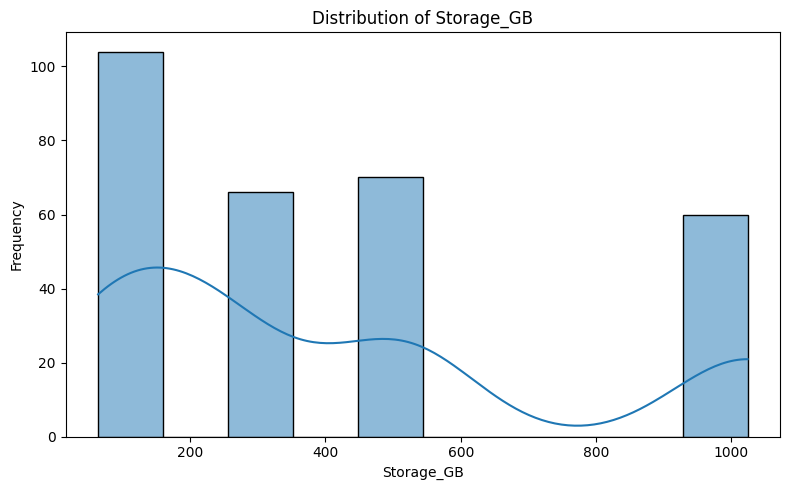

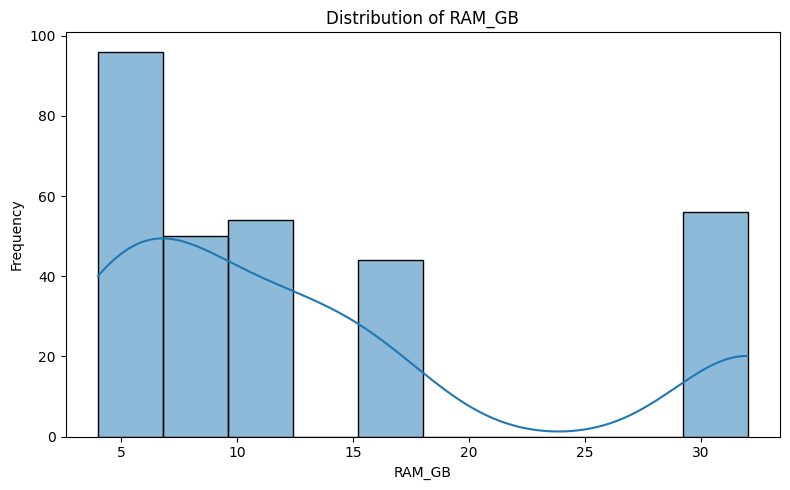

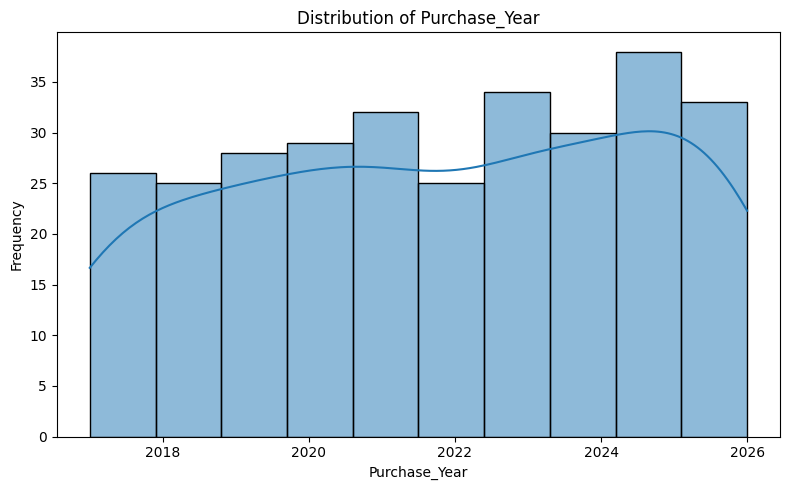

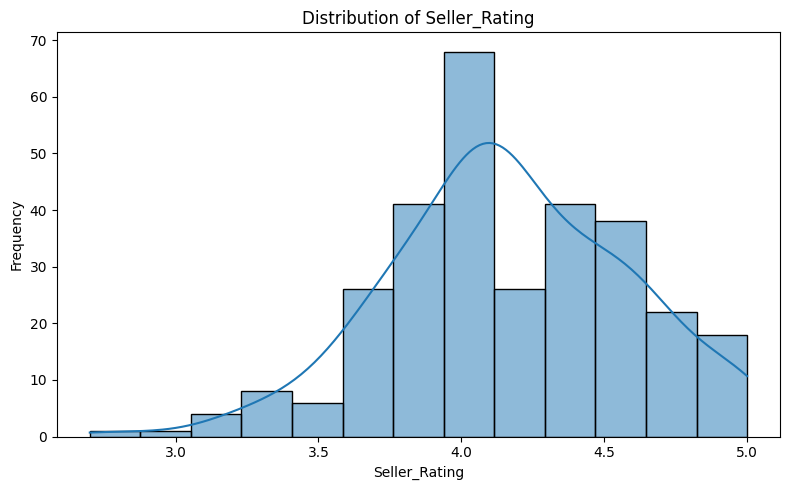

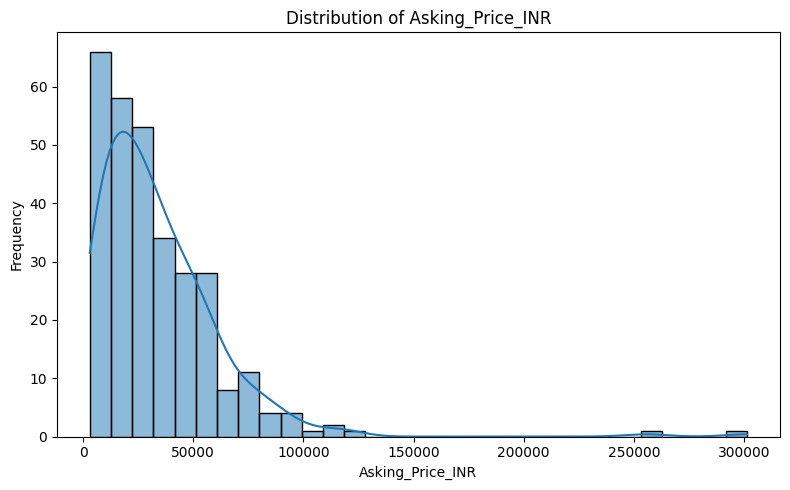

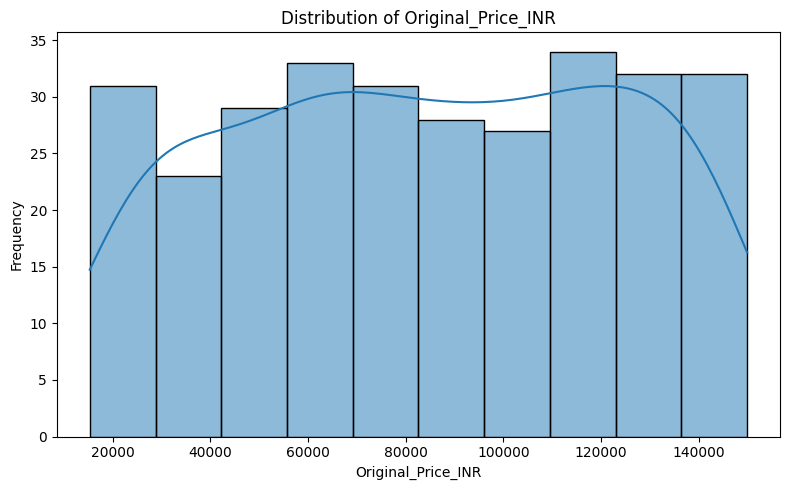

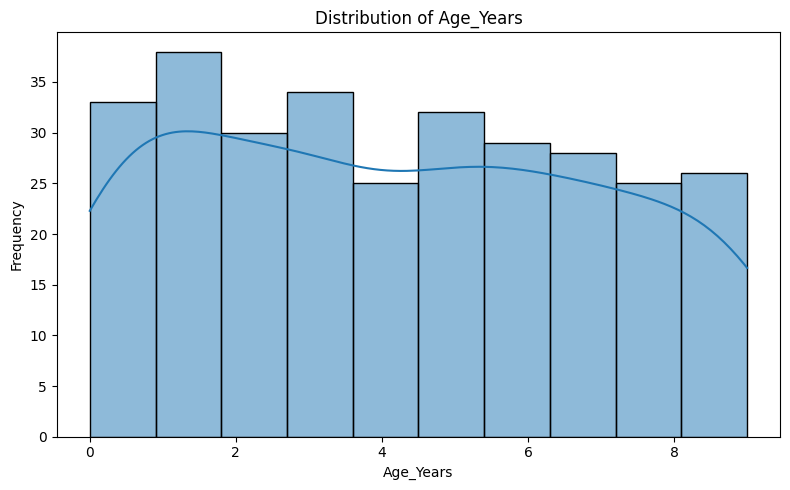

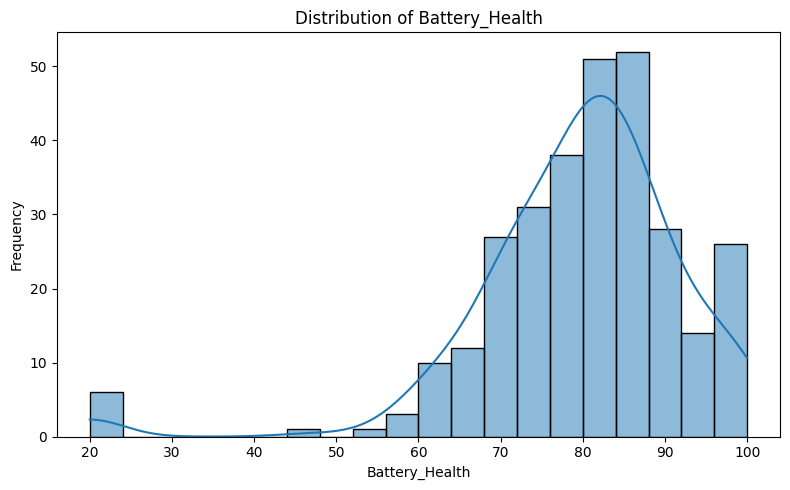

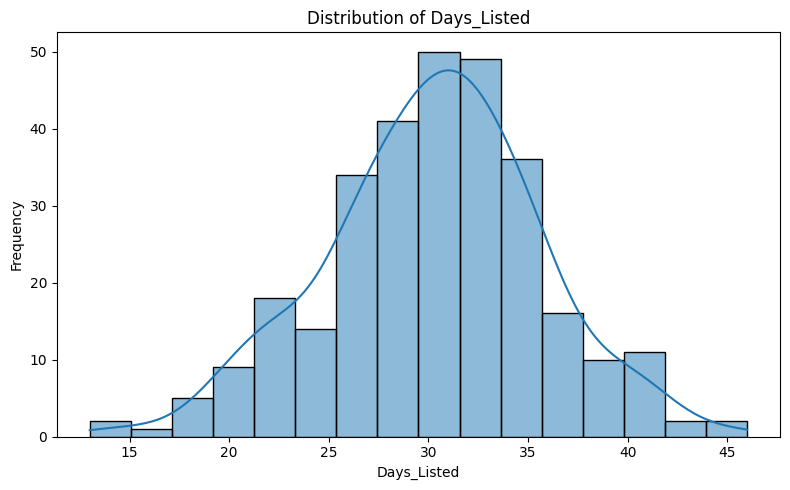

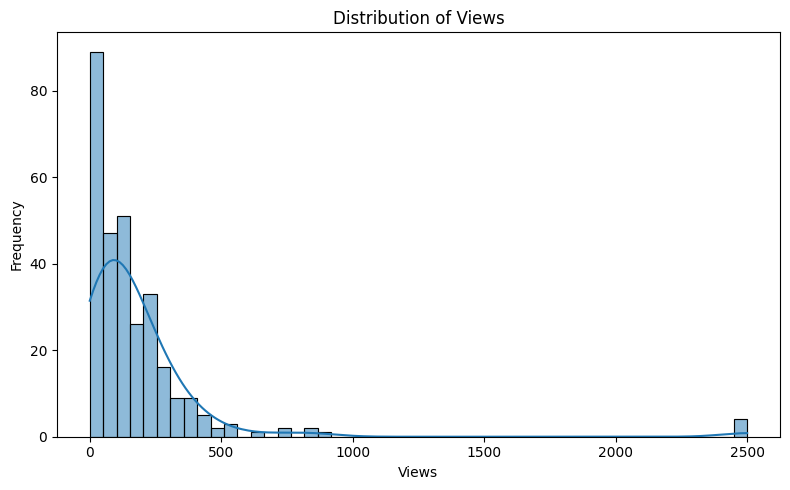

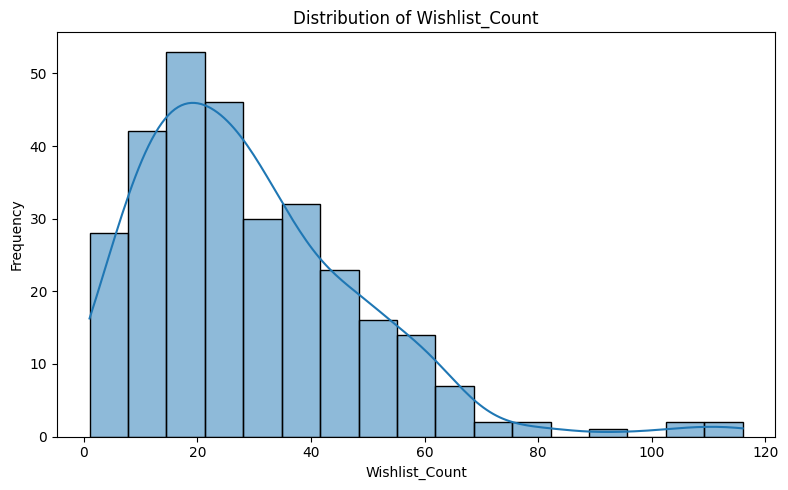

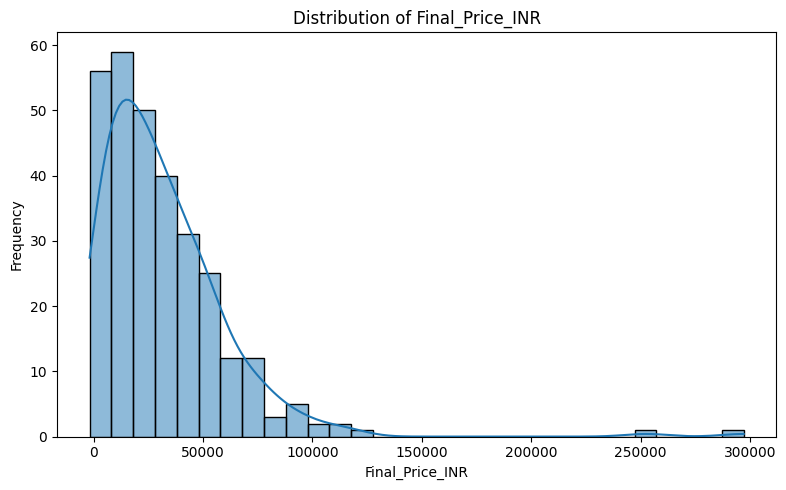

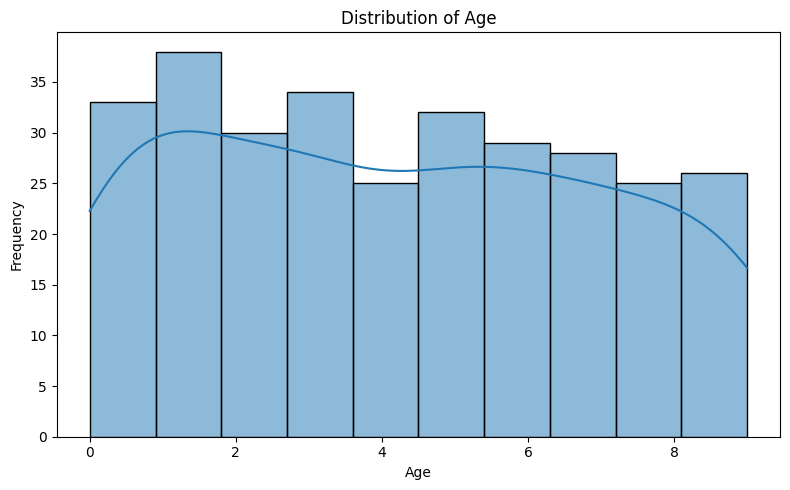

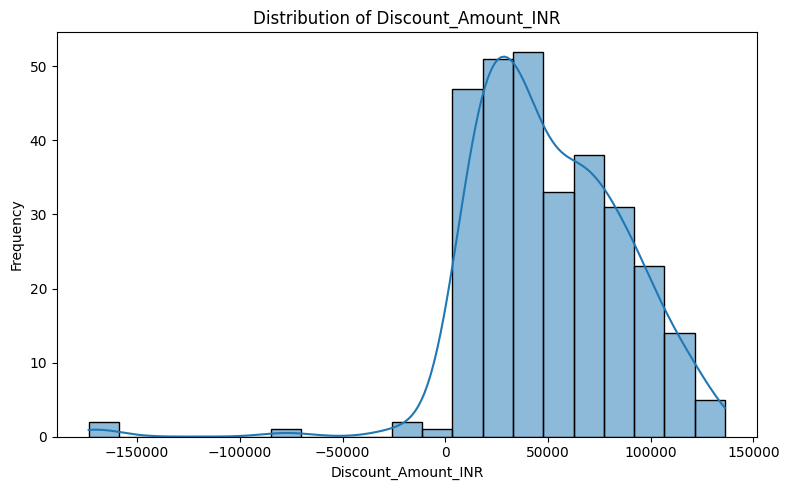

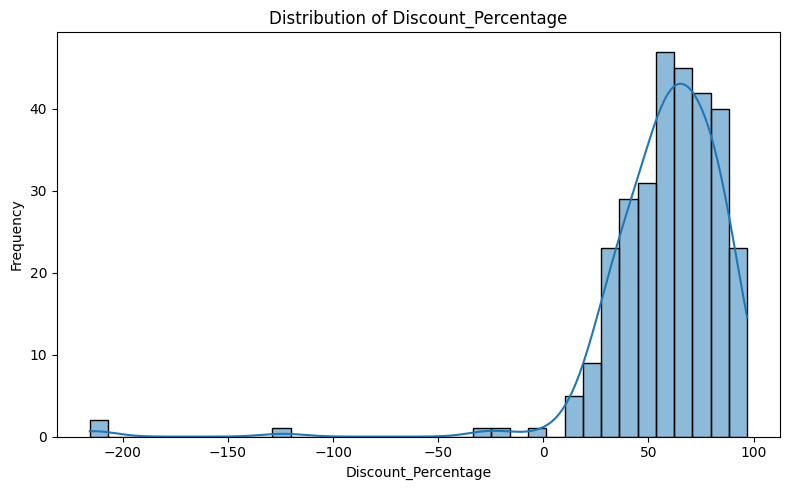

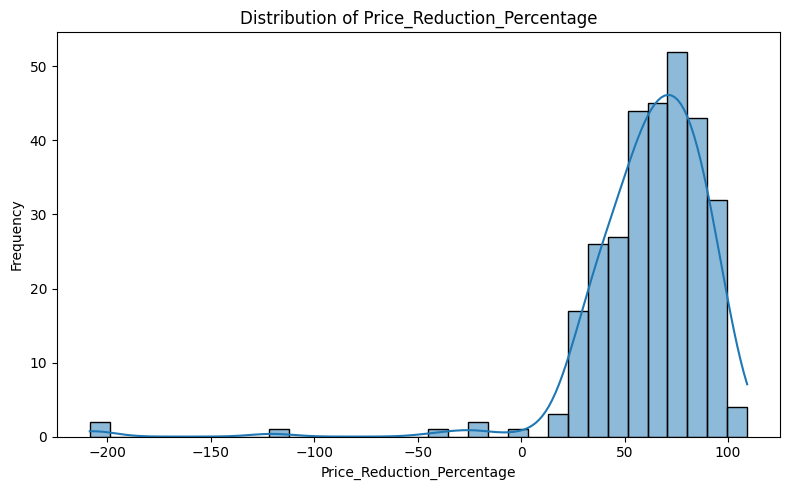

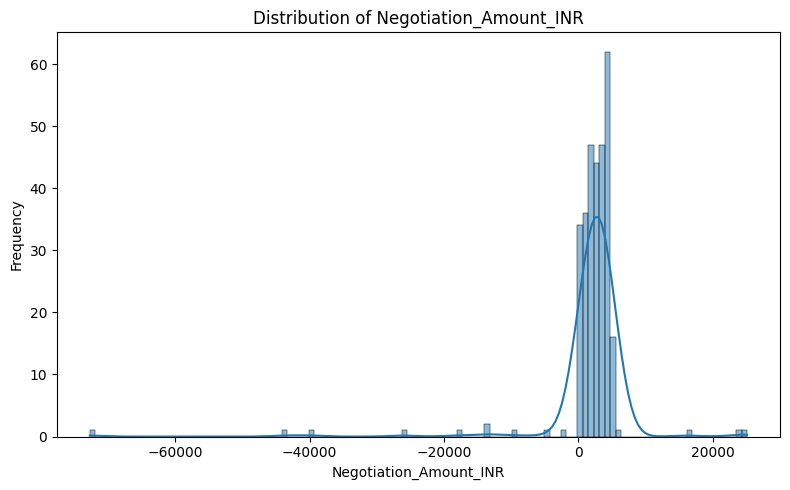

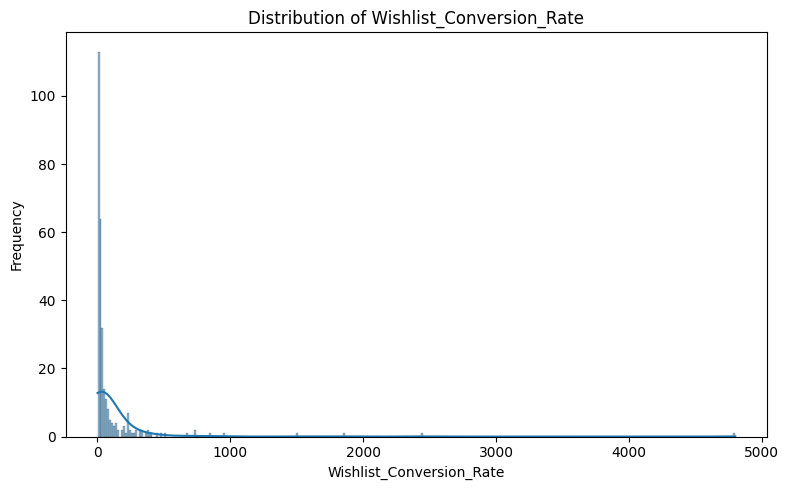

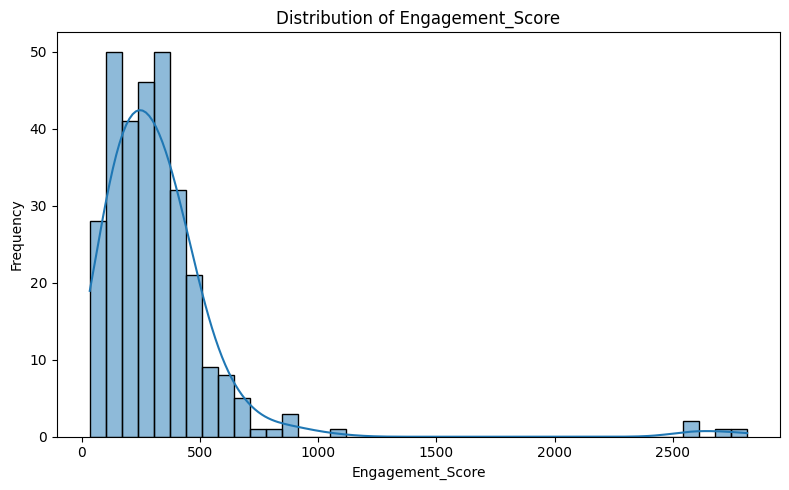

In [57]:
for column in numerical_columns:

    plt.figure(figsize=(8, 5))

    sns.histplot(
        data=df,
        x=column,
        kde=True
    )

    plt.title(f'Distribution of {column}')
    plt.xlabel(column)
    plt.ylabel('Frequency')
    plt.tight_layout()
    plt.show()

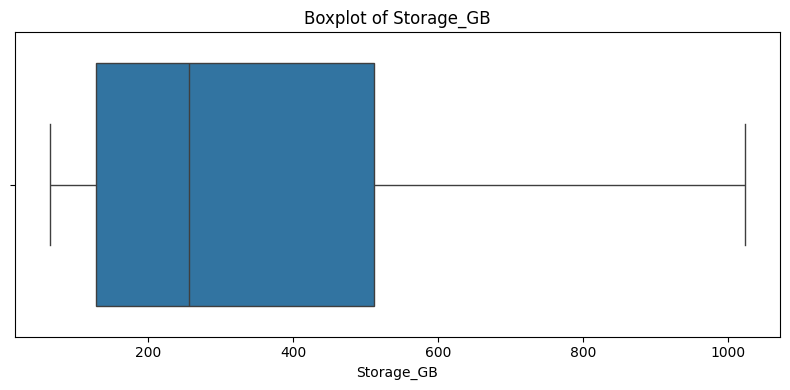

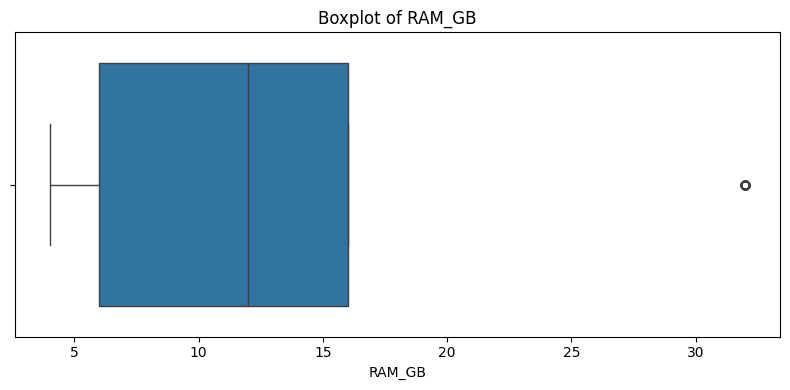

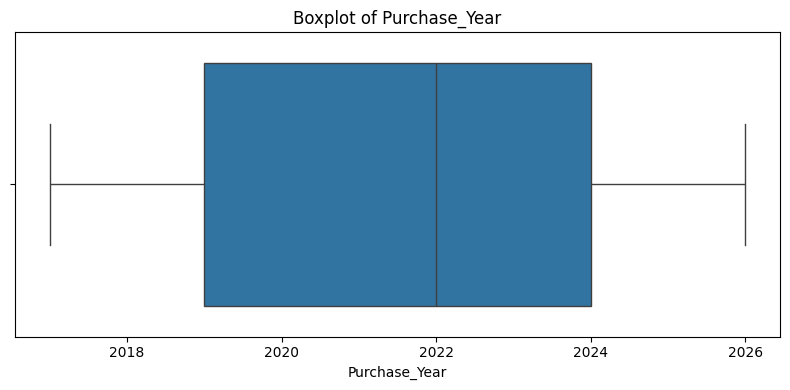

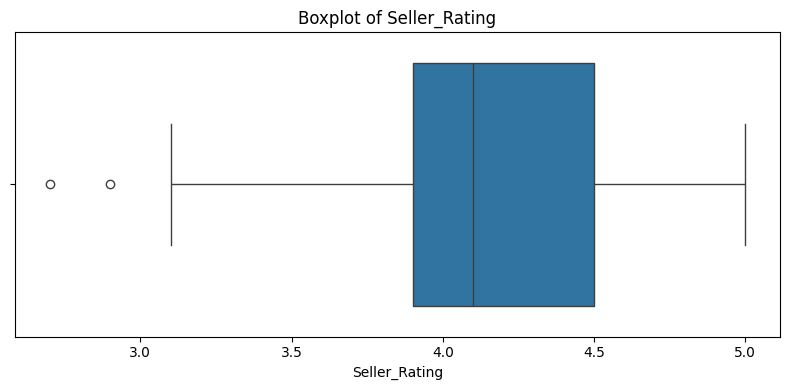

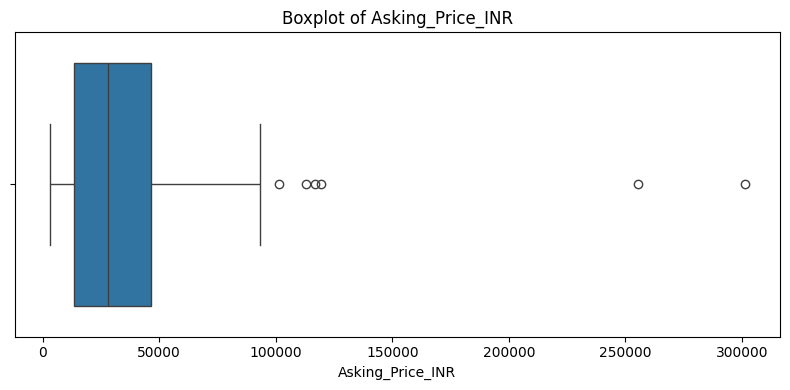

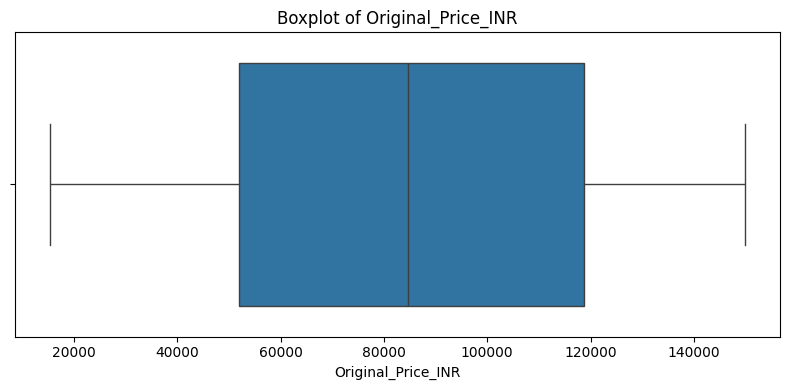

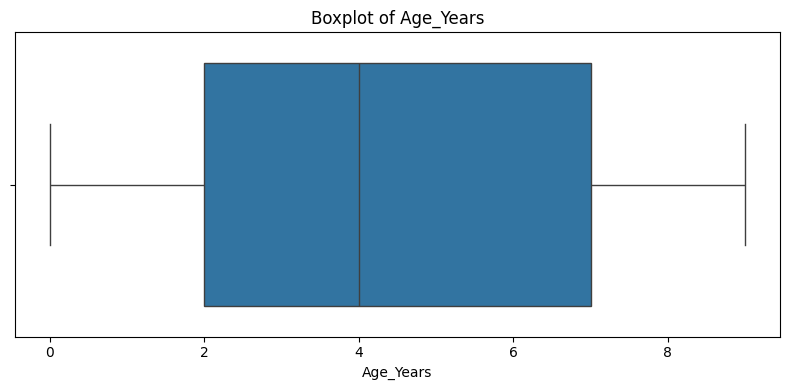

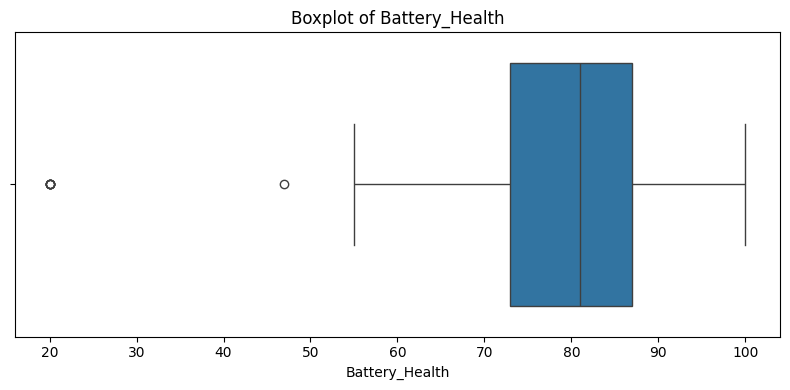

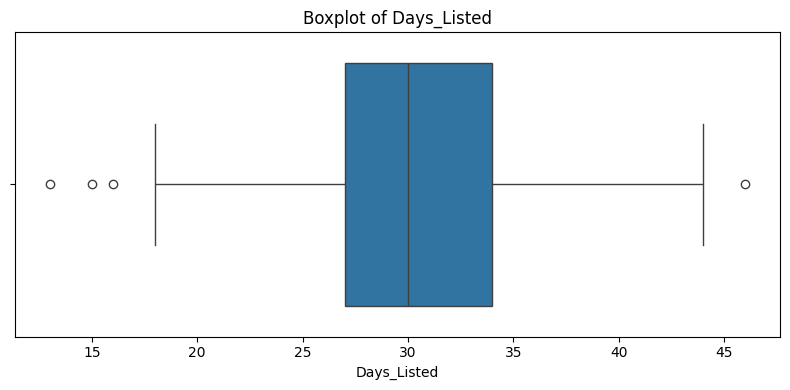

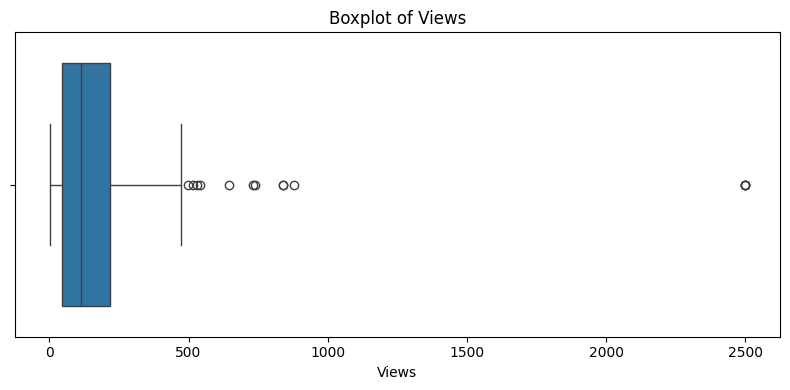

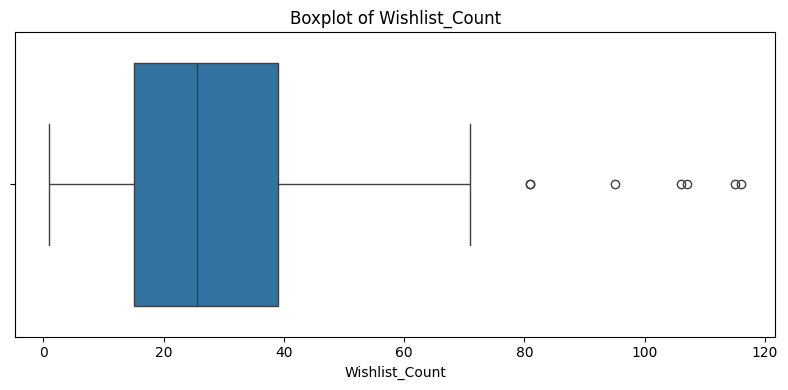

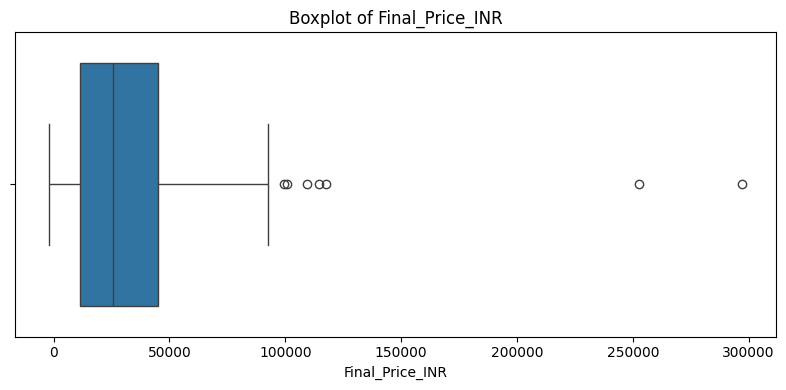

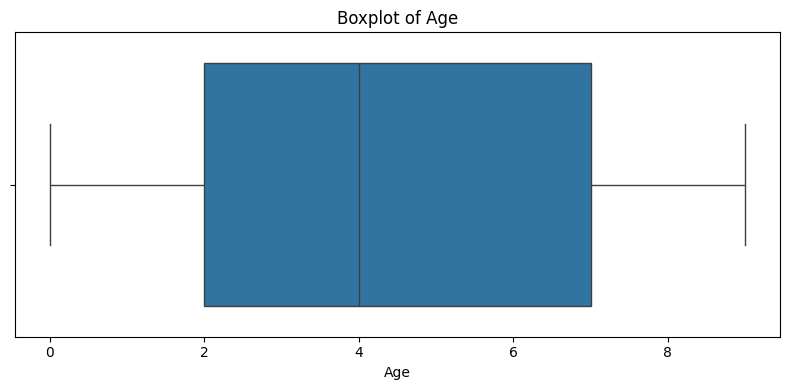

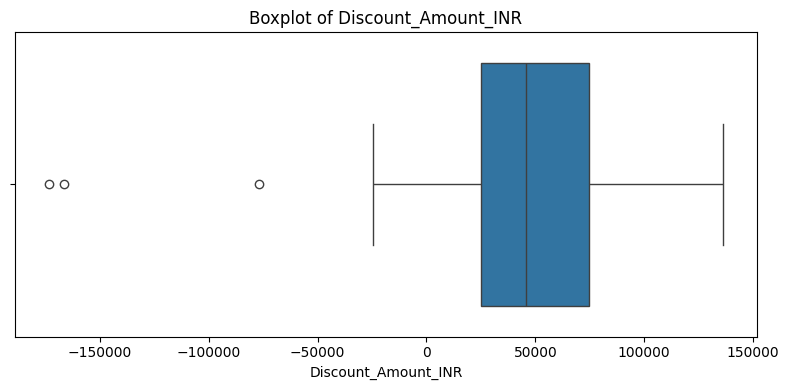

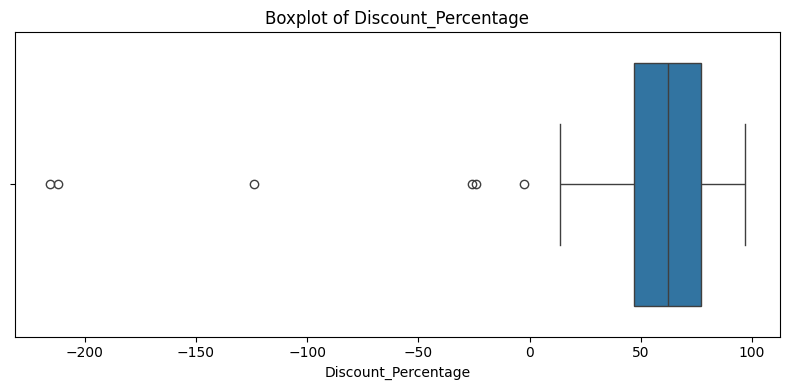

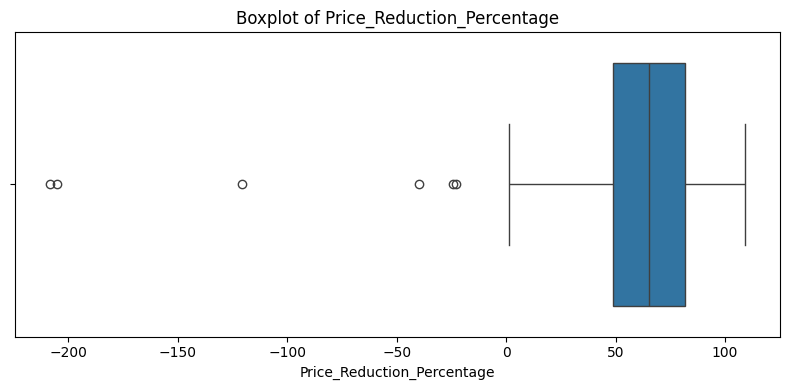

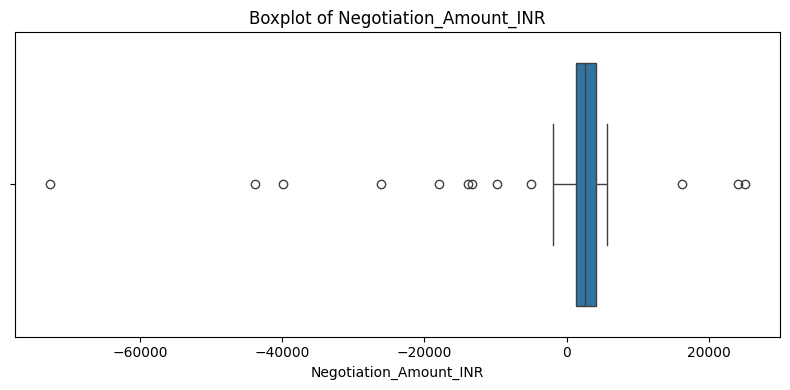

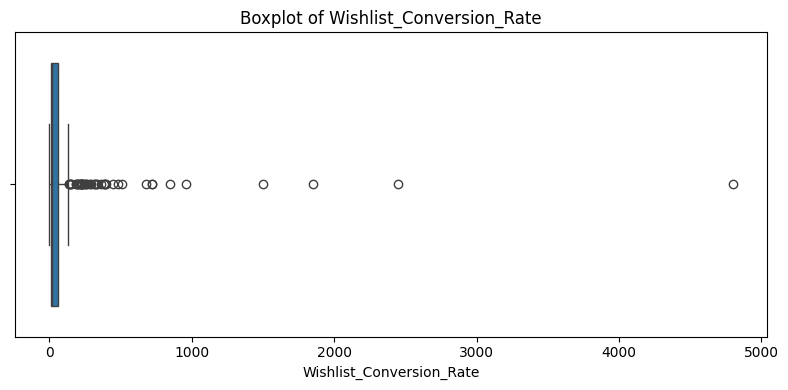

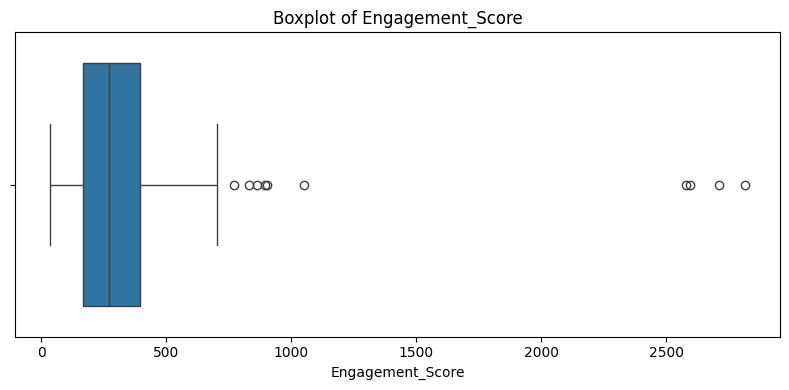

In [58]:
# Boxplots for numerical variables

for column in numerical_columns:

    plt.figure(figsize=(8, 4))

    sns.boxplot(
        x=df[column]
    )

    plt.title(f'Boxplot of {column}')
    plt.xlabel(column)
    plt.tight_layout()
    plt.show()

In [59]:
# Mean, median, standard deviation, min and max

univariate_summary = pd.DataFrame({
    'Mean': df[numerical_columns].mean(),
    'Median': df[numerical_columns].median(),
    'Std_Dev': df[numerical_columns].std(),
    'Minimum': df[numerical_columns].min(),
    'Maximum': df[numerical_columns].max(),
    'Skewness': df[numerical_columns].skew()
})

display(univariate_summary)

,Mean,Median,Std_Dev,Minimum,Maximum,Skewness
Storage_GB,413.866667,256.000000,343.449405,64.000000,1024.000000,0.830466
RAM_GB,13.386667,12.000000,9.718298,4.000000,32.000000,1.075590
Purchase_Year,2021.786667,2022.000000,2.868551,2017.000000,2026.000000,-0.125591
Seller_Rating,4.163333,4.100000,0.421879,2.700000,5.000000,-0.169827
Asking_Price_INR,33931.266667,27997.000000,30606.690307,3000.000000,301430.000000,3.906743
Original_Price_INR,84234.523333,84602.000000,39170.317484,15314.000000,149932.000000,-0.055774
Age_Years,4.213333,4.000000,2.868551,0.000000,9.000000,0.125591
Battery_Health,79.486667,81.000000,13.001537,20.000000,100.000000,-1.863871
Days_Listed,30.236667,30.000000,5.395463,13.000000,46.000000,-0.152003
Views,180.943333,115.000000,307.306184,1.000000,2500.000000,5.939276


In [60]:
categorical_columns = df.select_dtypes(
    include=['object', 'category']
).columns

print("Categorical columns:")
print(list(categorical_columns))

Categorical columns:
['Listing_ID', 'Seller_ID', 'Product_Name', 'Brand', 'Category', 'Condition', 'Warranty_Status', 'City', 'Negotiation_Level', 'Sale_Status', 'Customer_Type', 'Advertisement_Text', 'Manufacture_Code', 'Favorite_Color', 'Device_Age_Category', 'Price_Category']


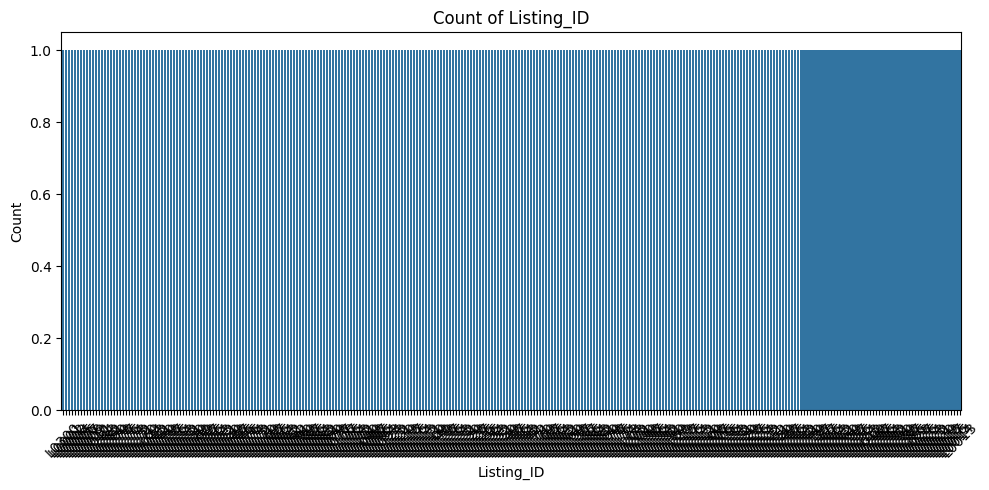

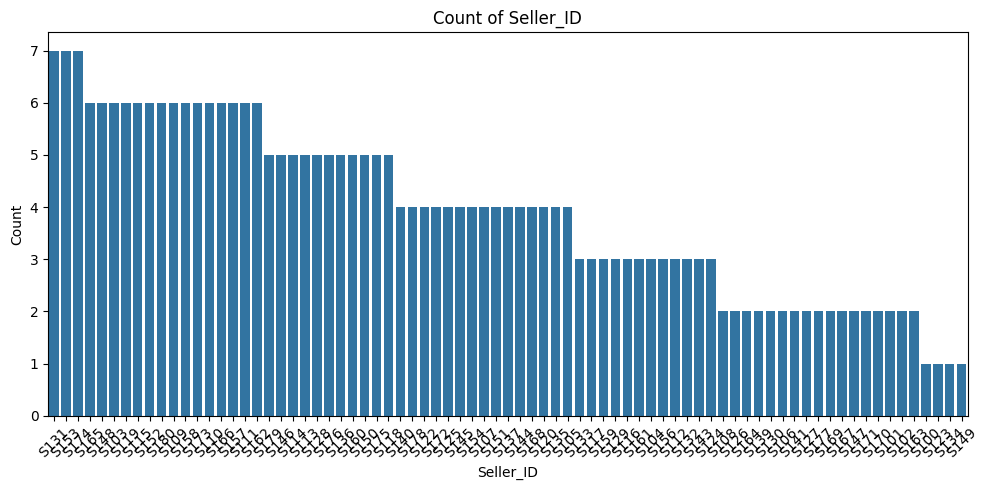

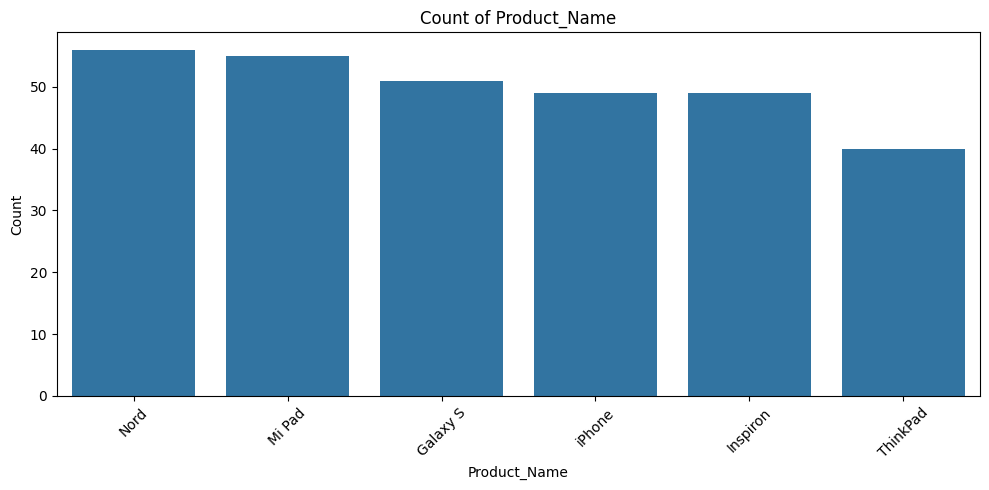

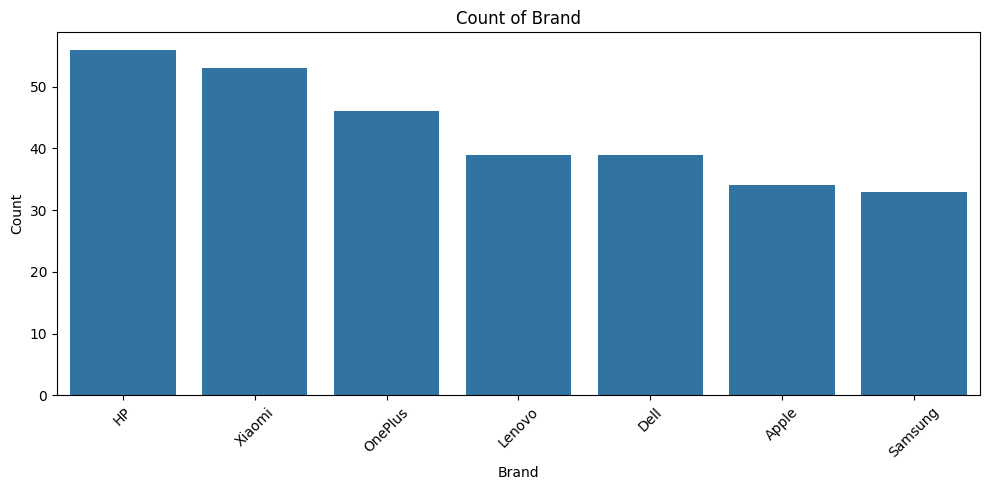

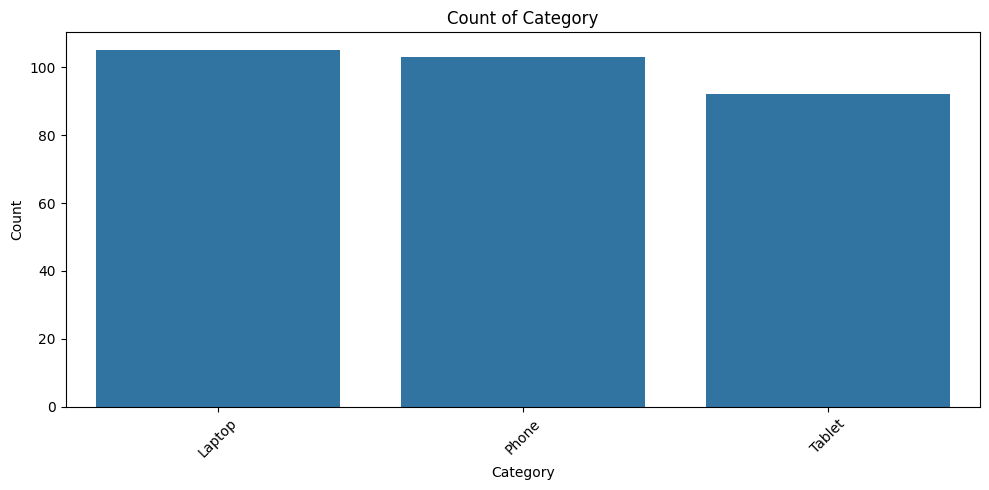

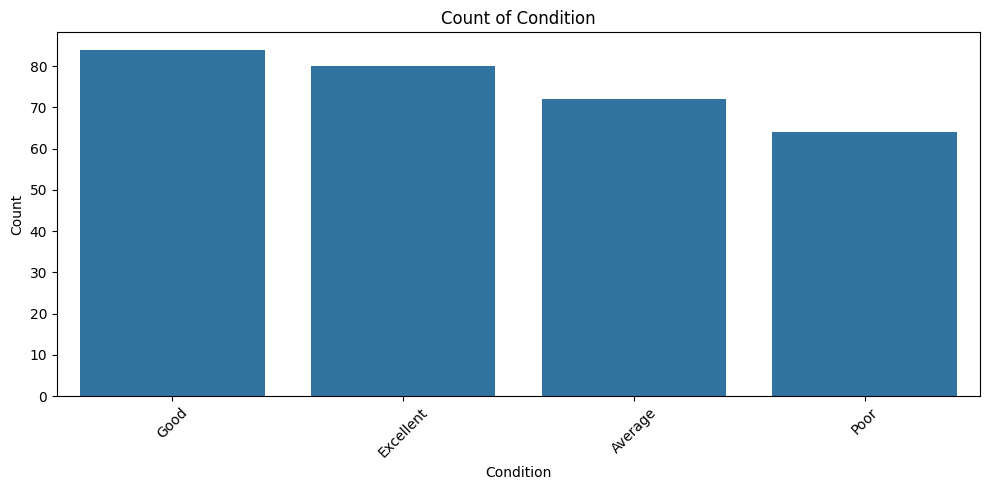

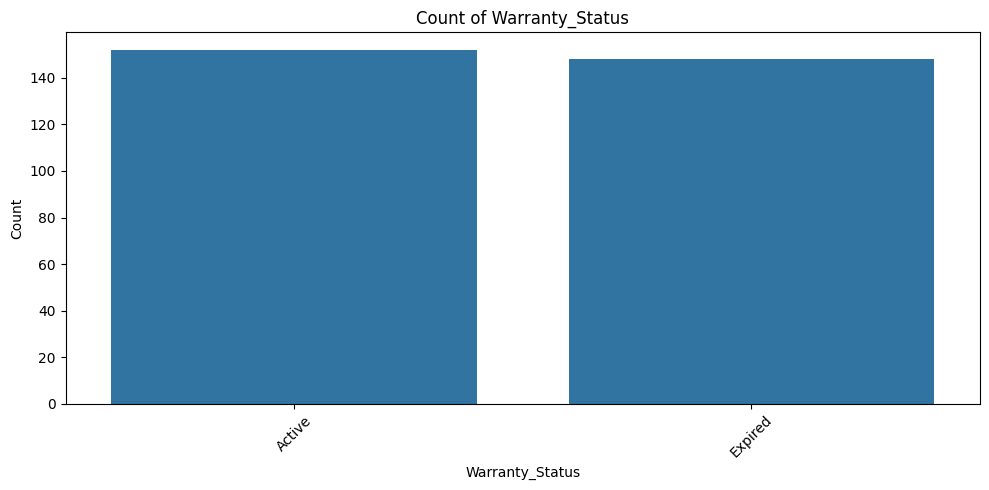

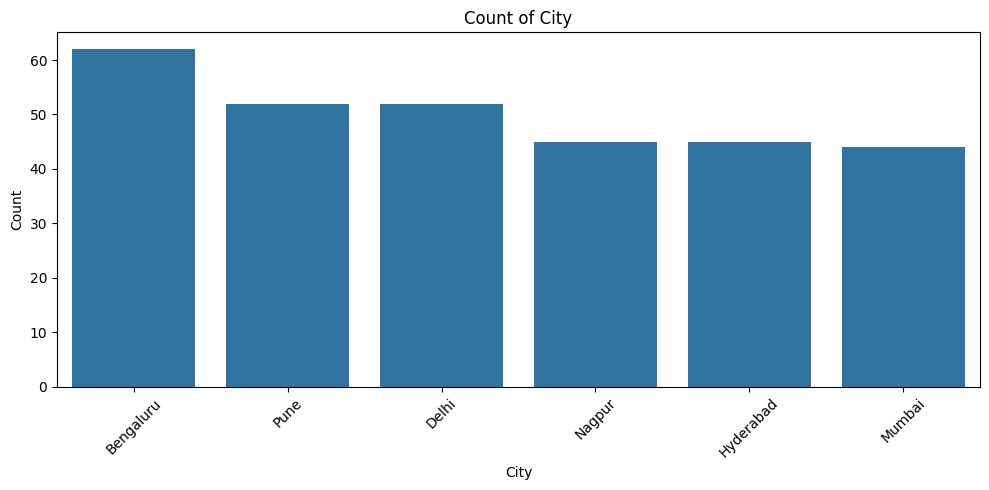

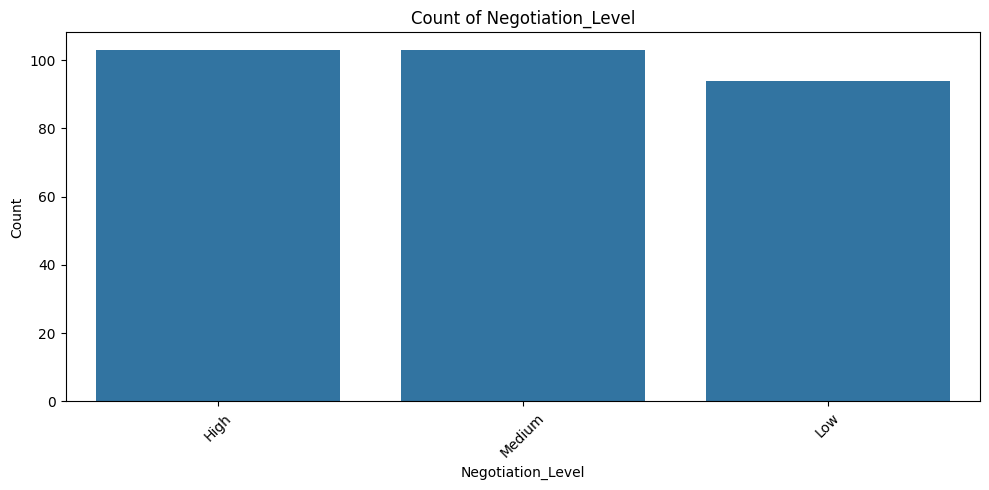

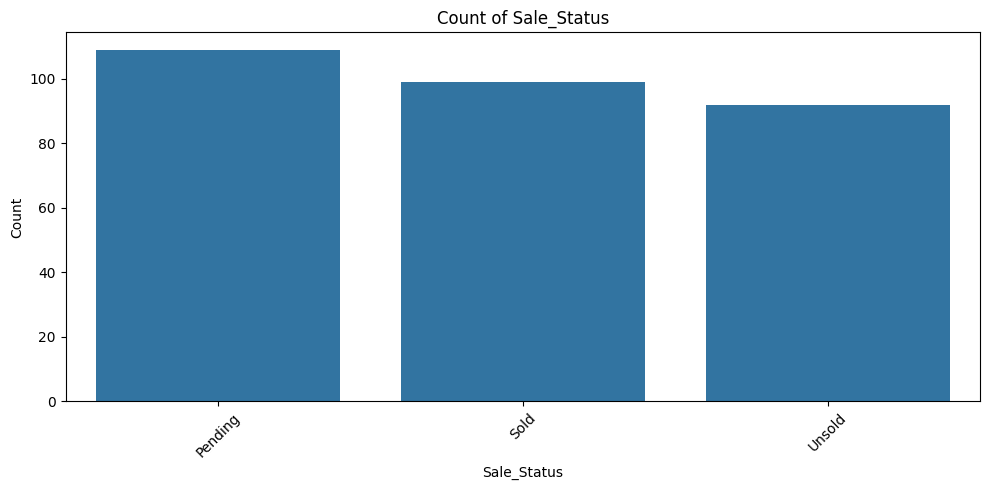

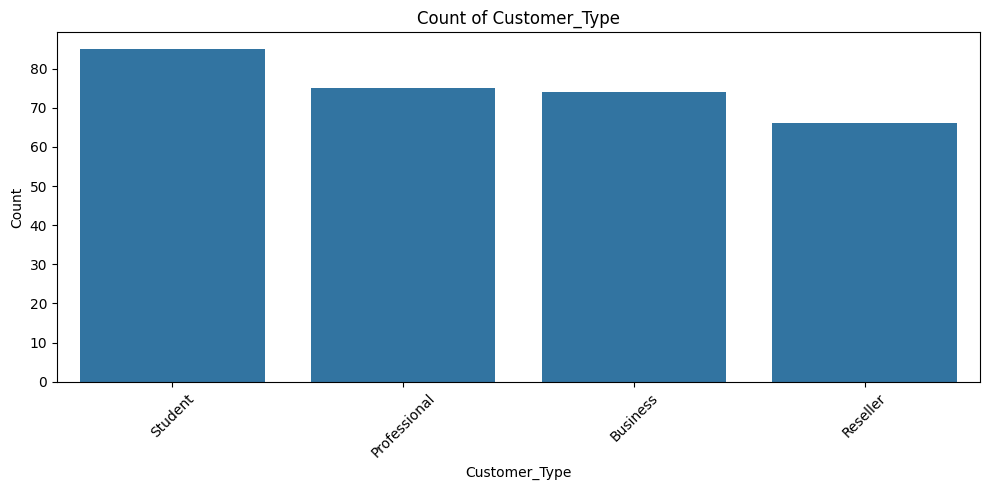

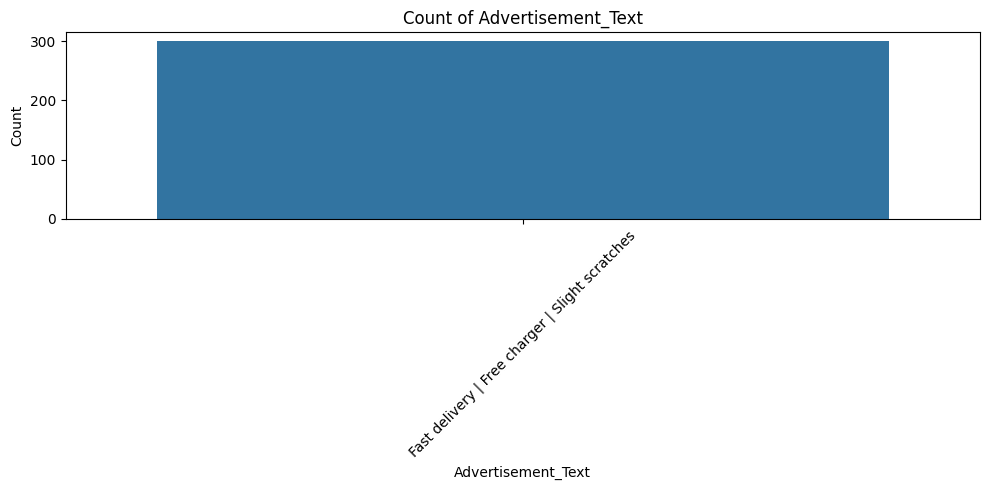

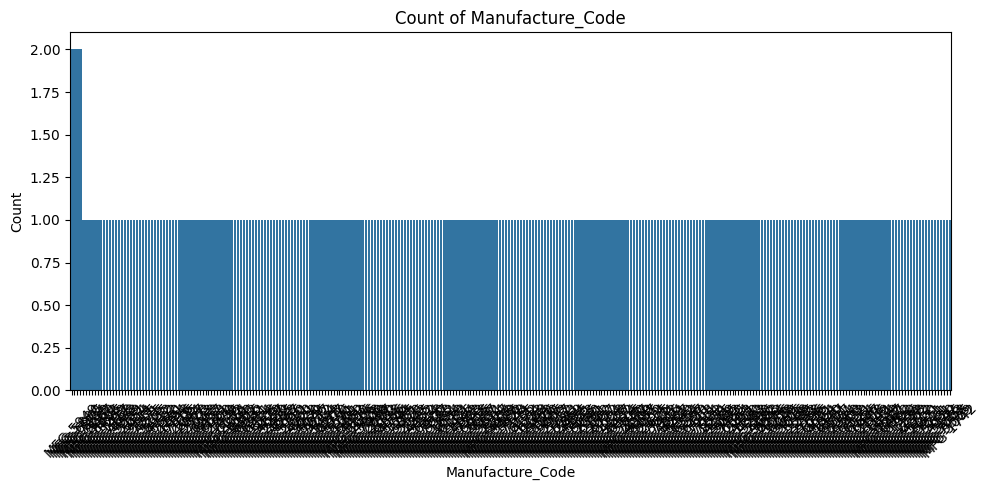

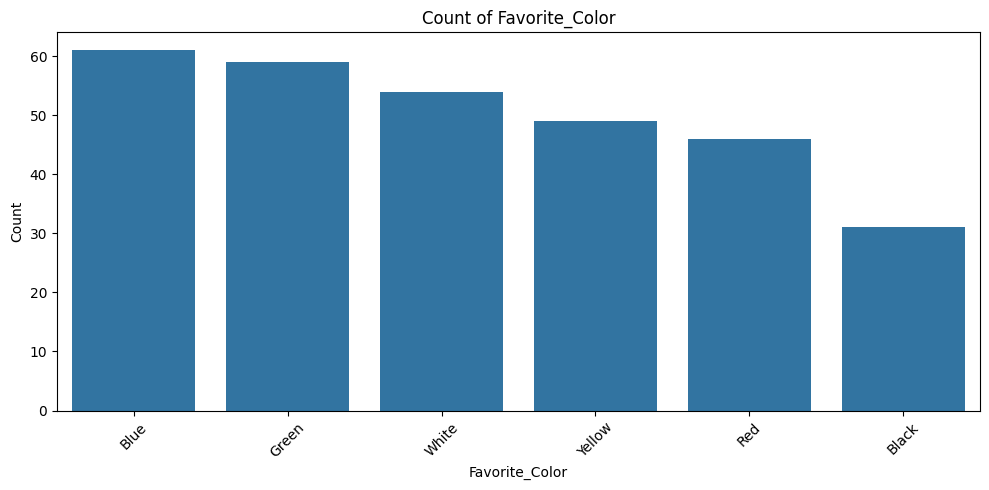

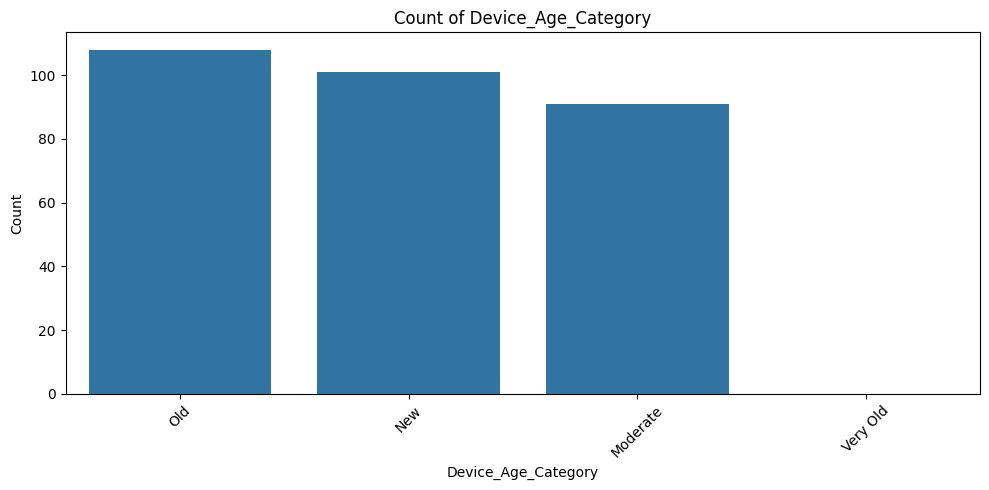

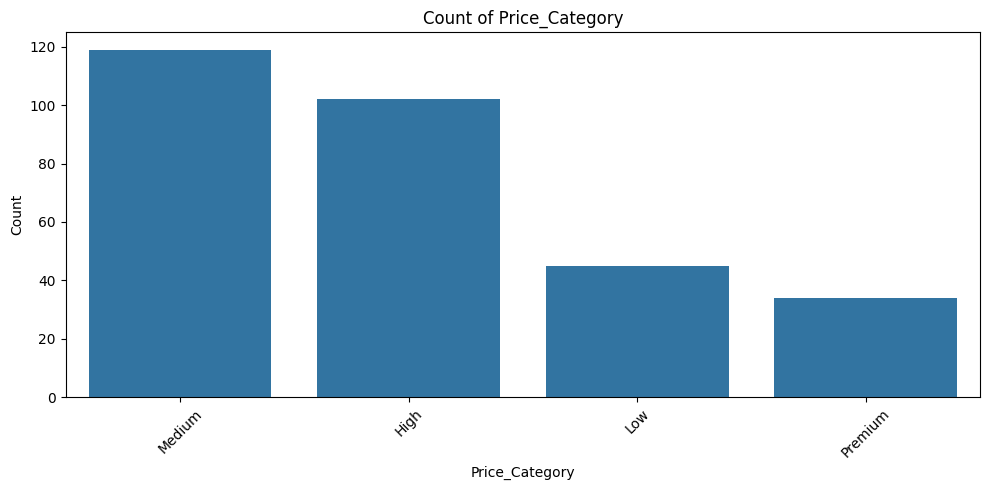

In [61]:
for column in categorical_columns:

    plt.figure(figsize=(10, 5))

    sns.countplot(
        data=df,
        x=column,
        order=df[column].value_counts().index
    )

    plt.title(f'Count of {column}')
    plt.xlabel(column)
    plt.ylabel('Count')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

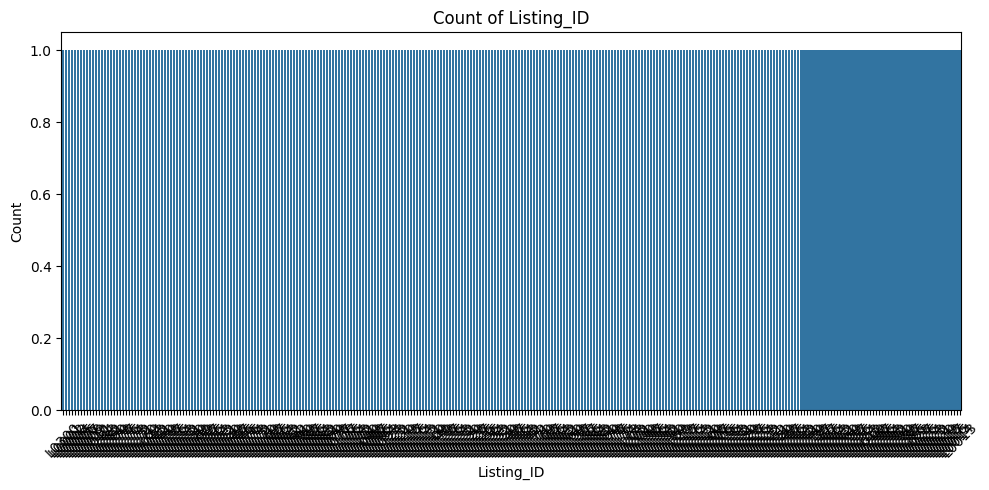

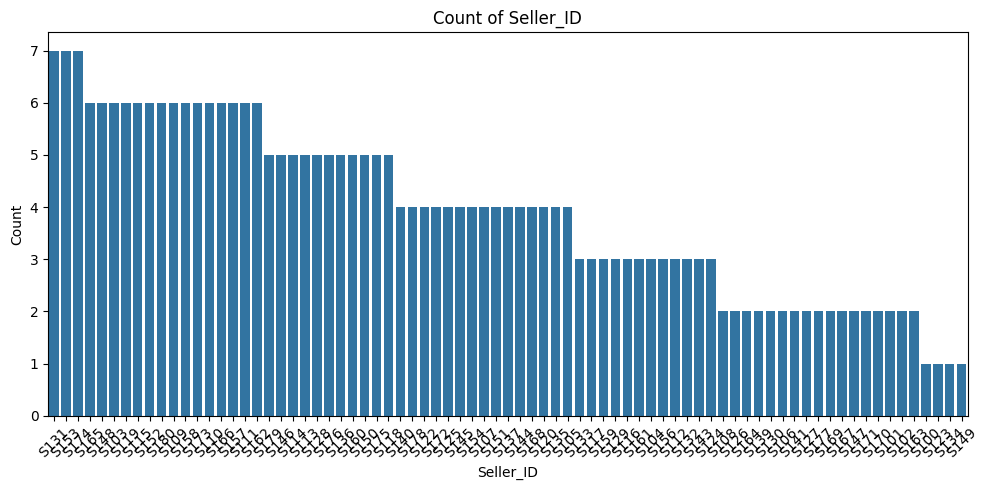

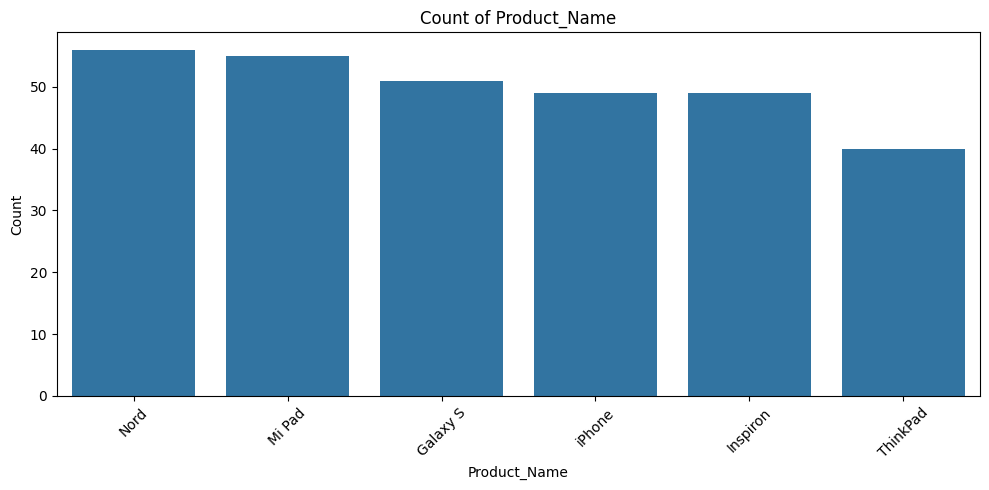

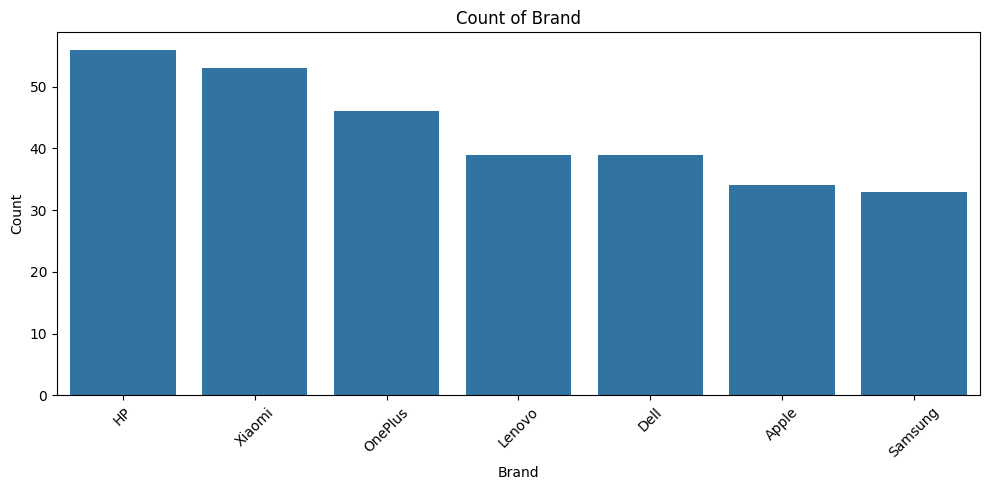

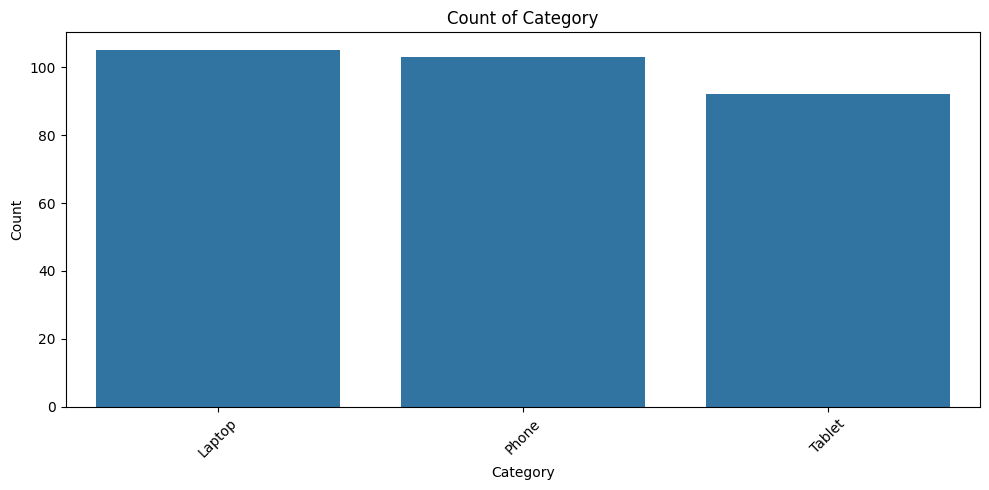

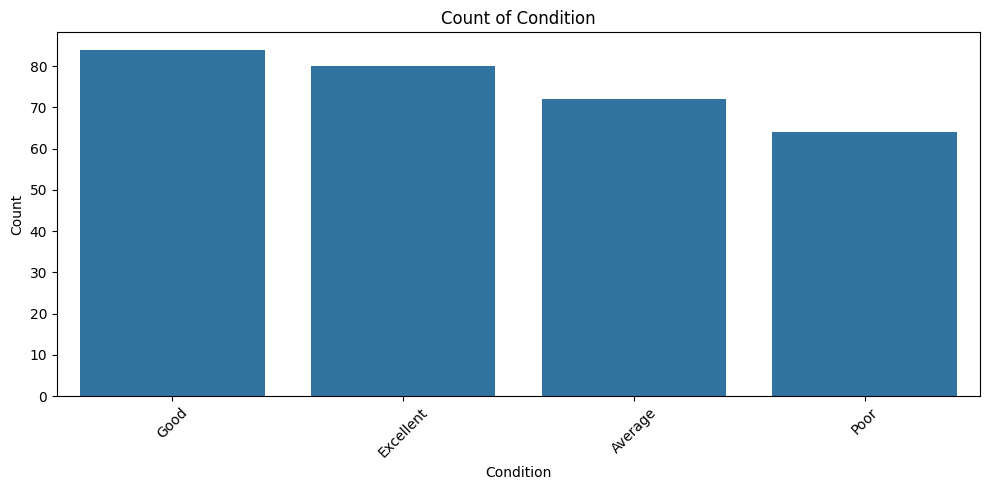

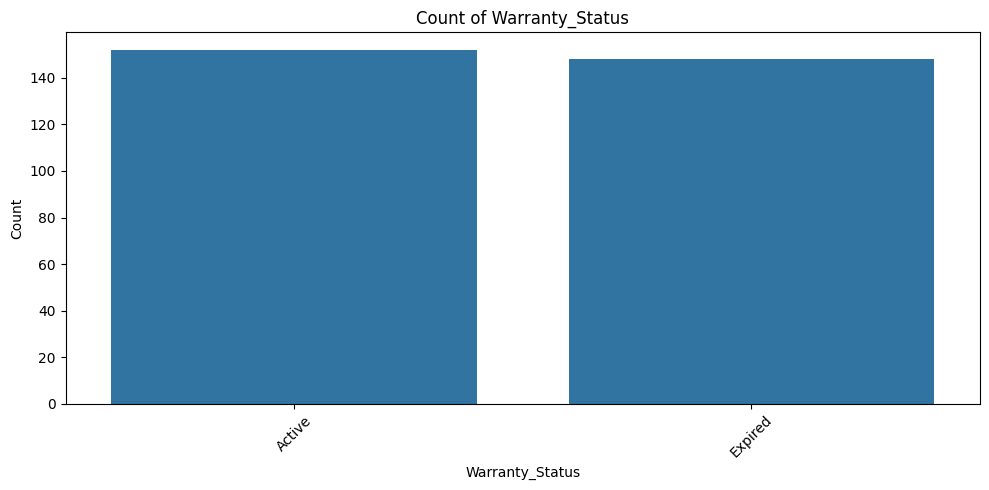

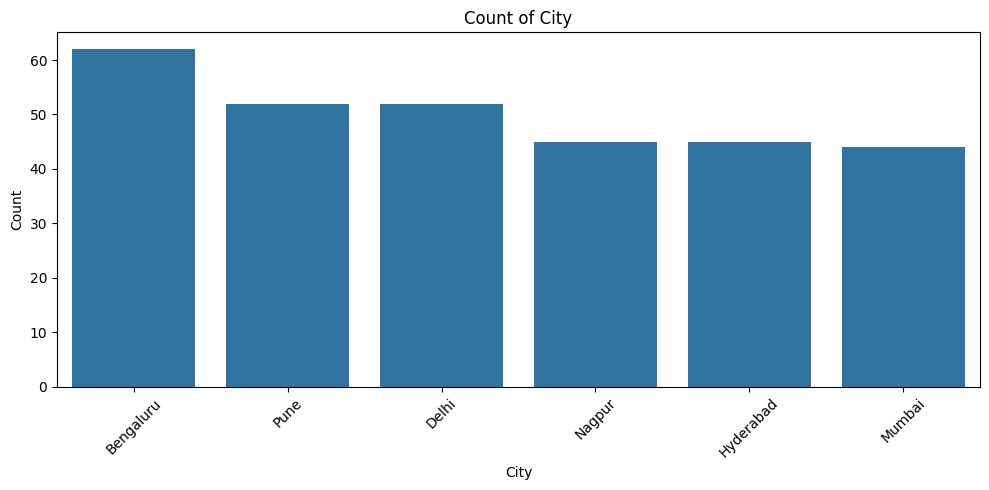

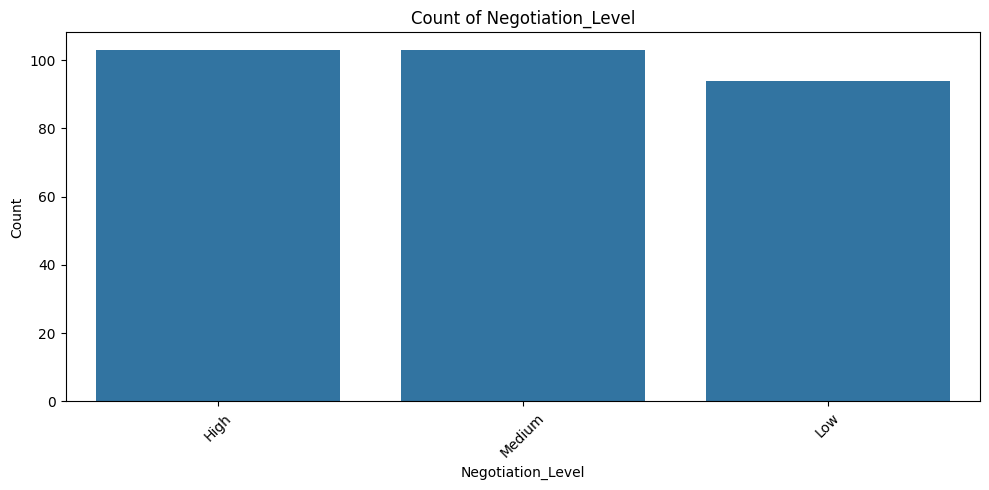

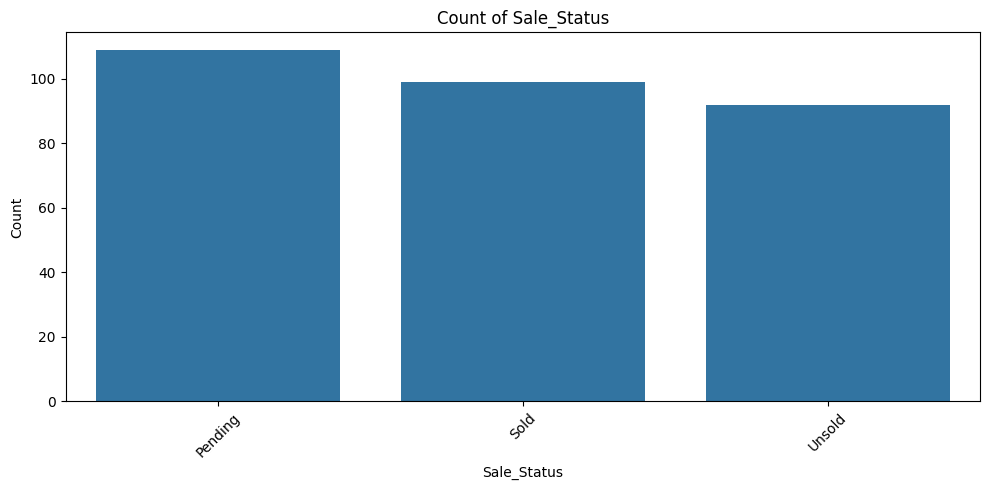

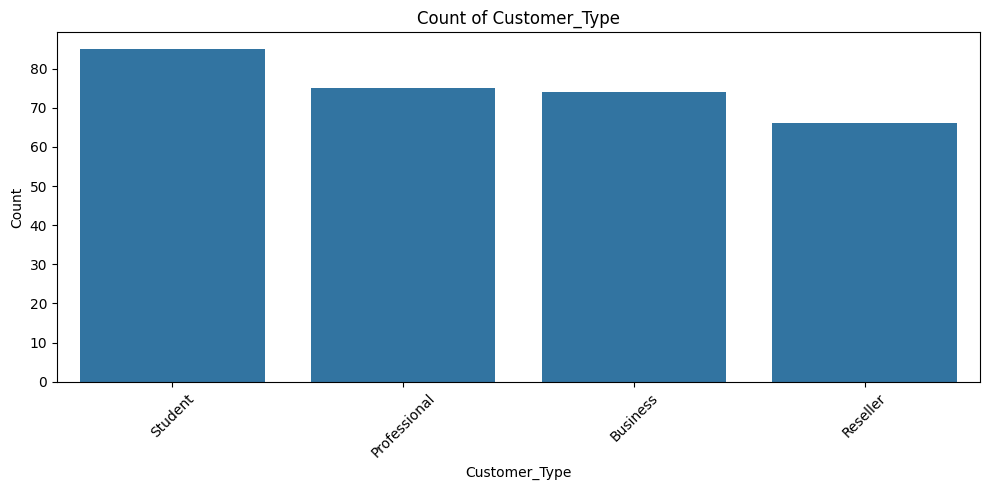

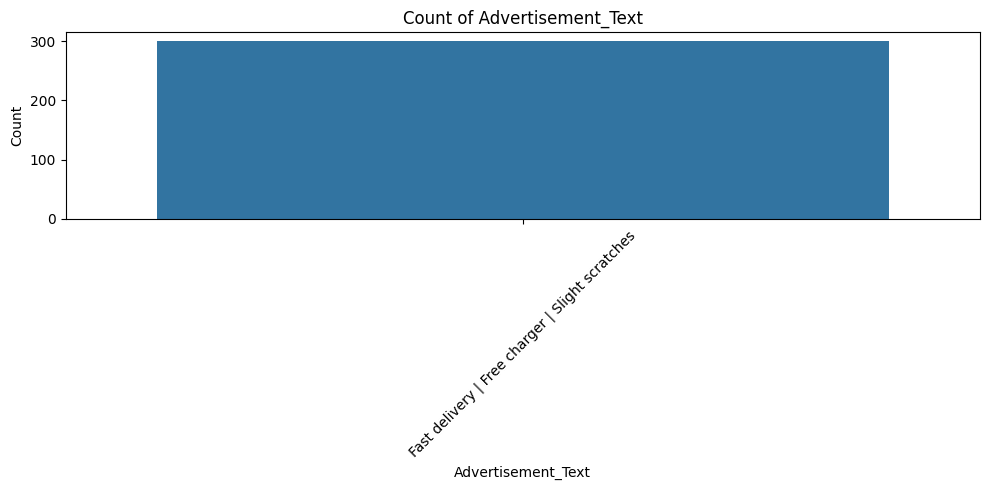

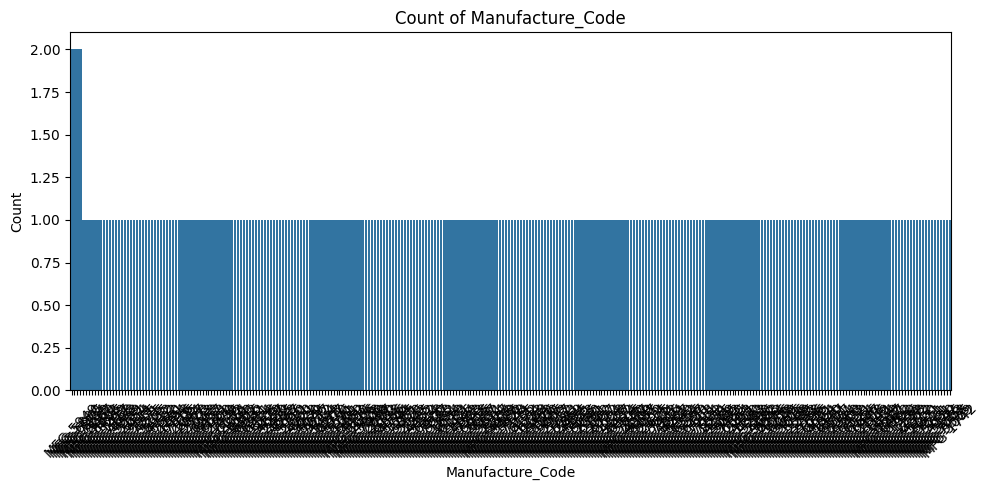

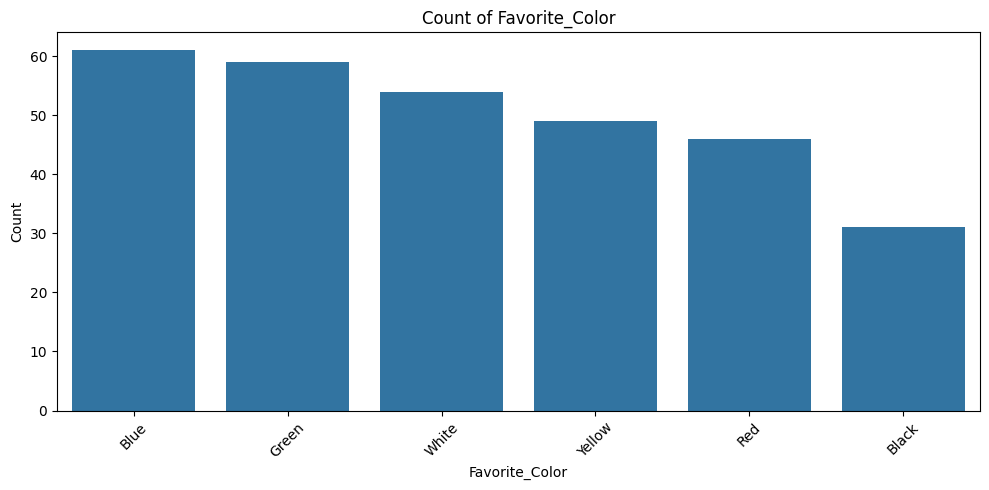

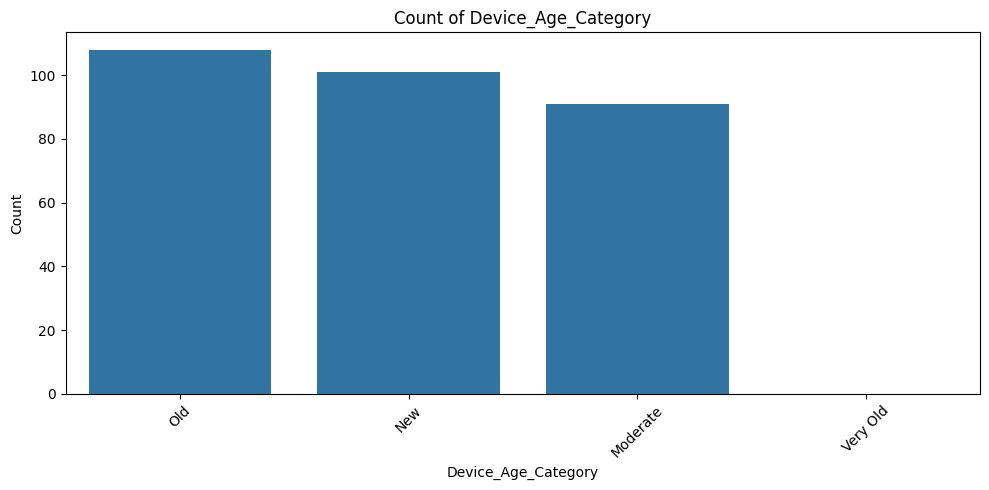

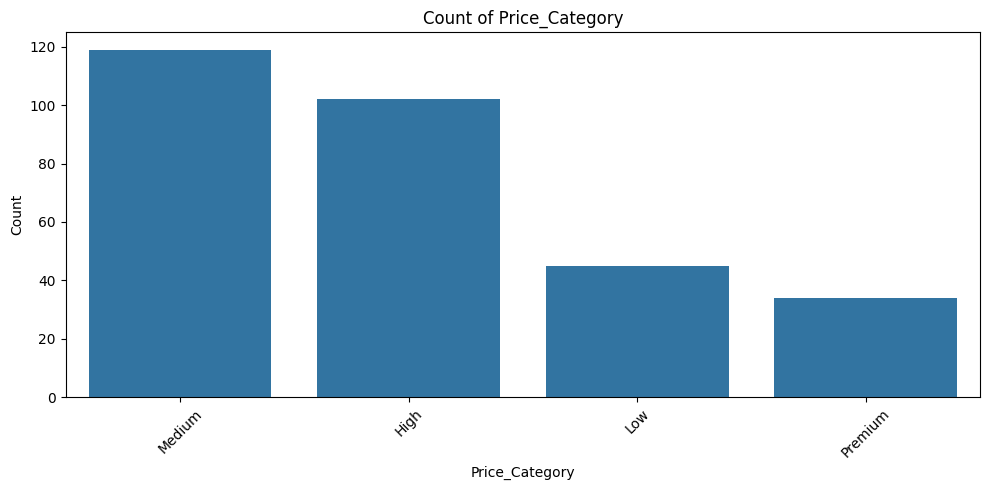

In [62]:
for column in categorical_columns:

    plt.figure(figsize=(10, 5))

    sns.countplot(
        data=df,
        x=column,
        order=df[column].value_counts().index
    )

    plt.title(f'Count of {column}')
    plt.xlabel(column)
    plt.ylabel('Count')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

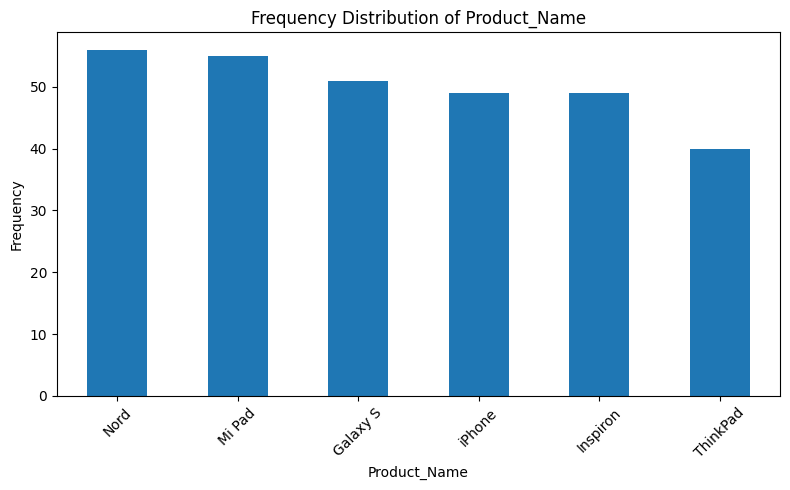

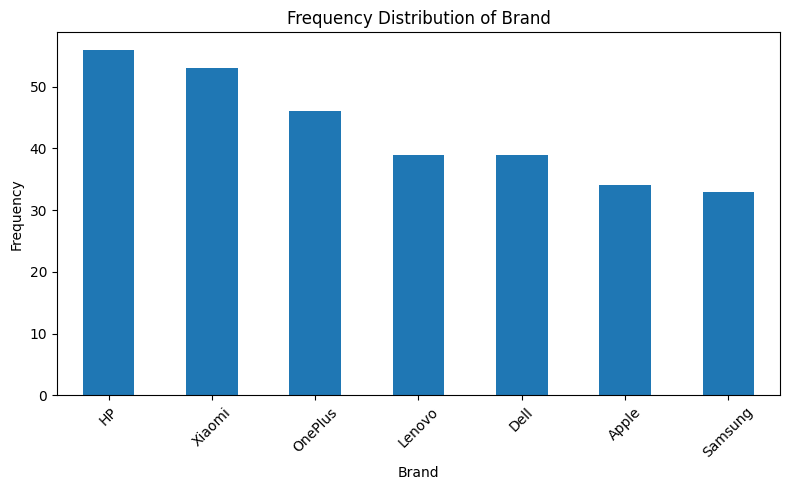

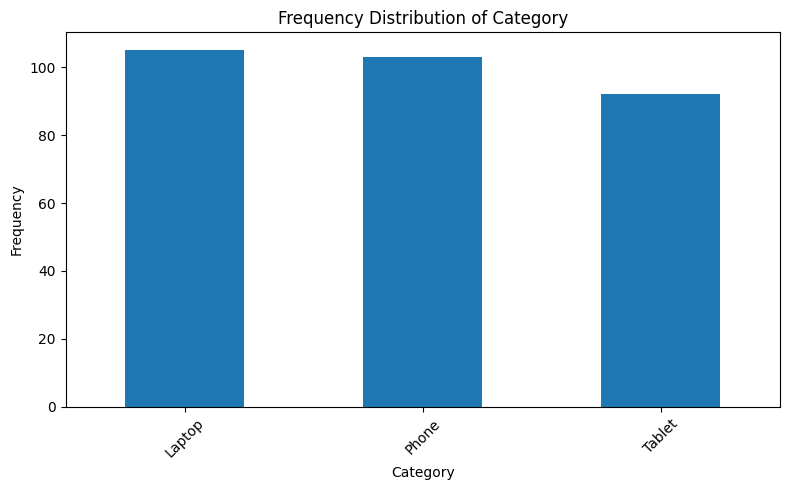

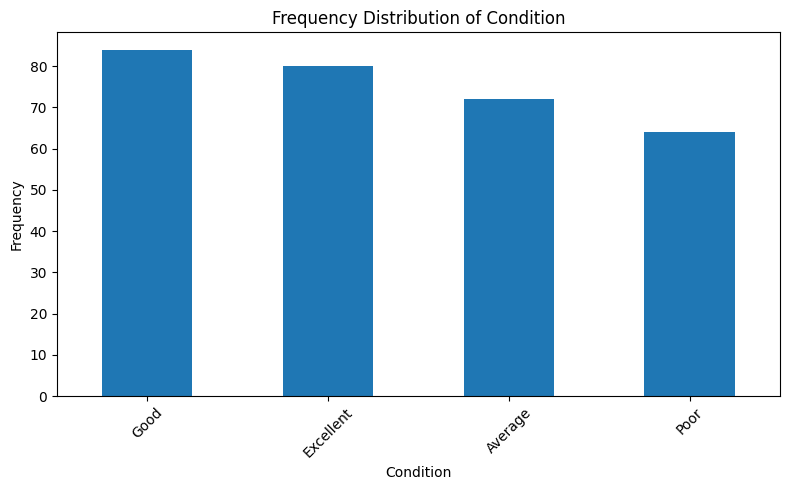

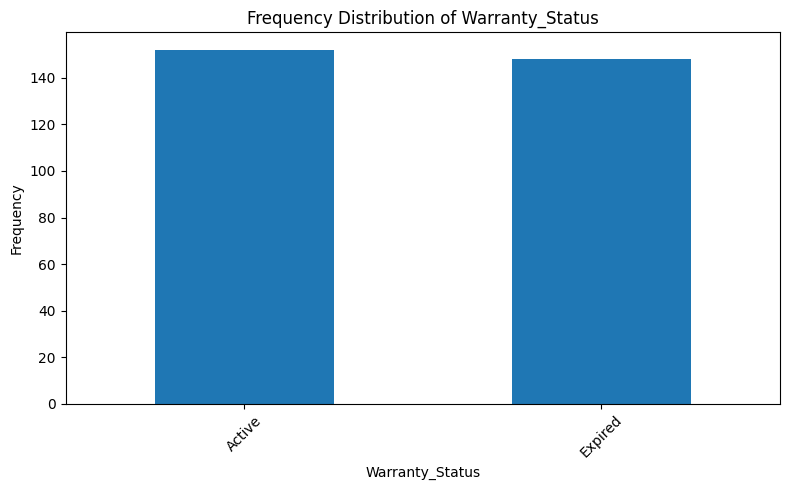

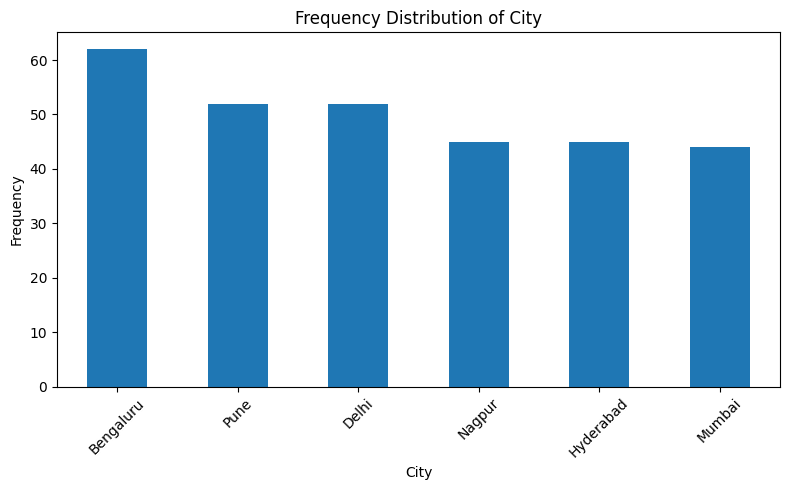

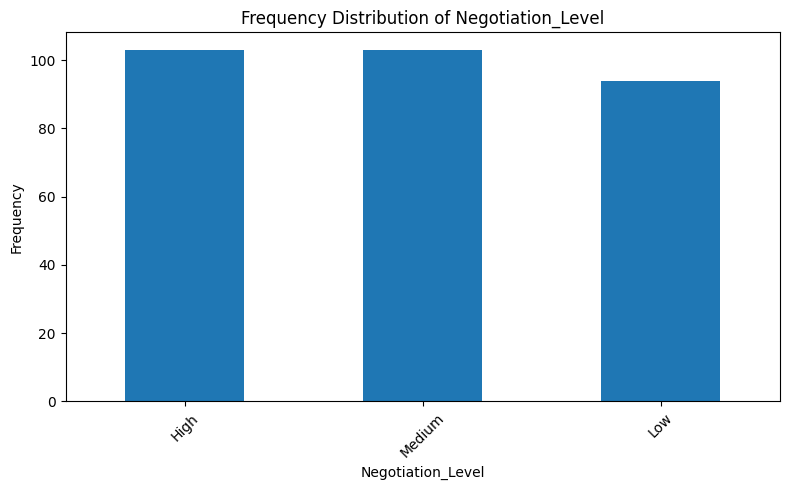

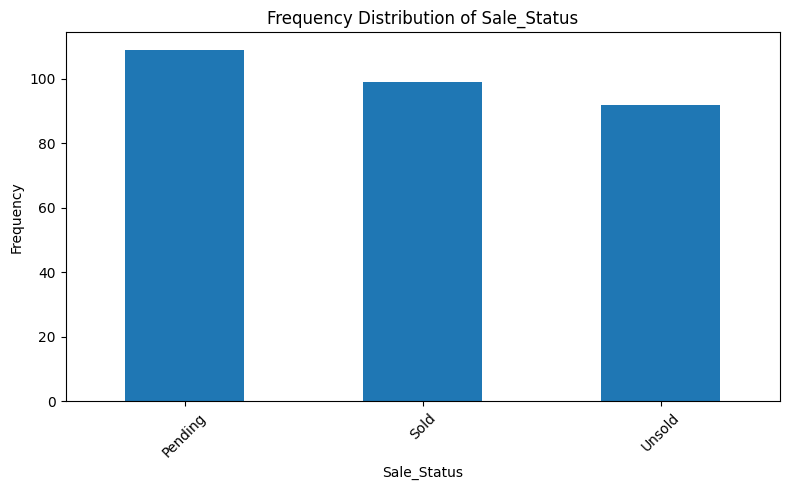

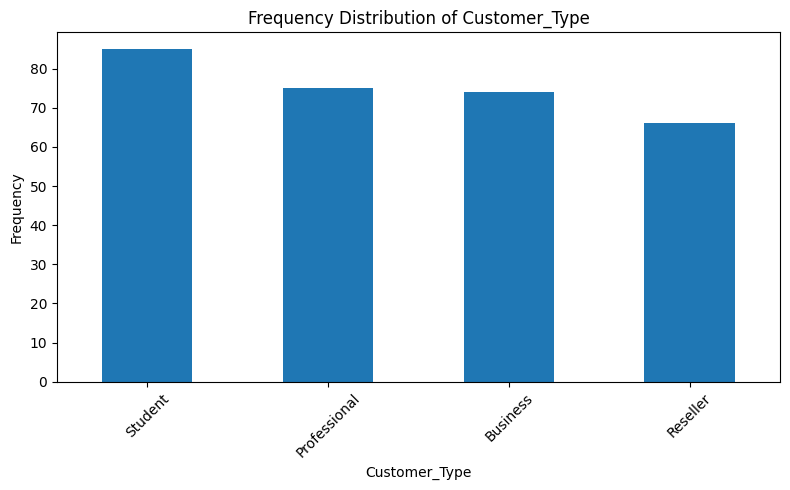

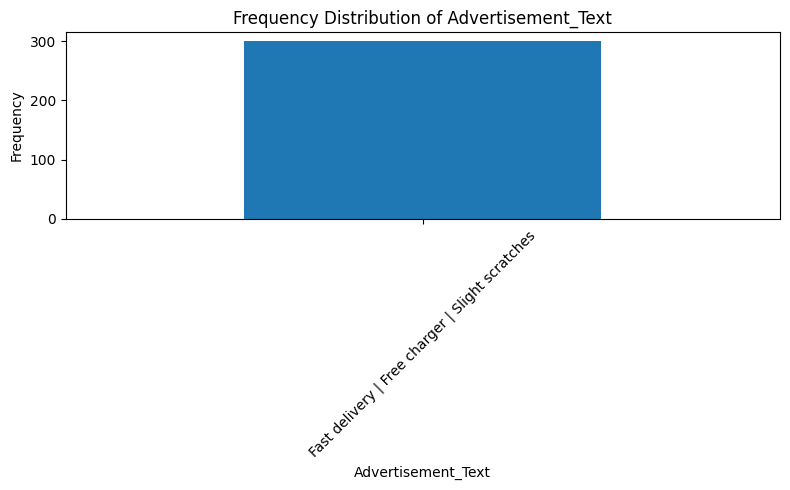

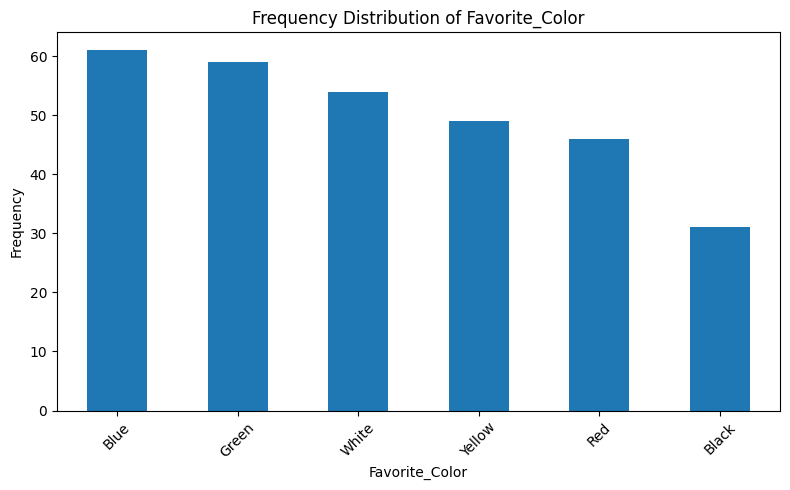

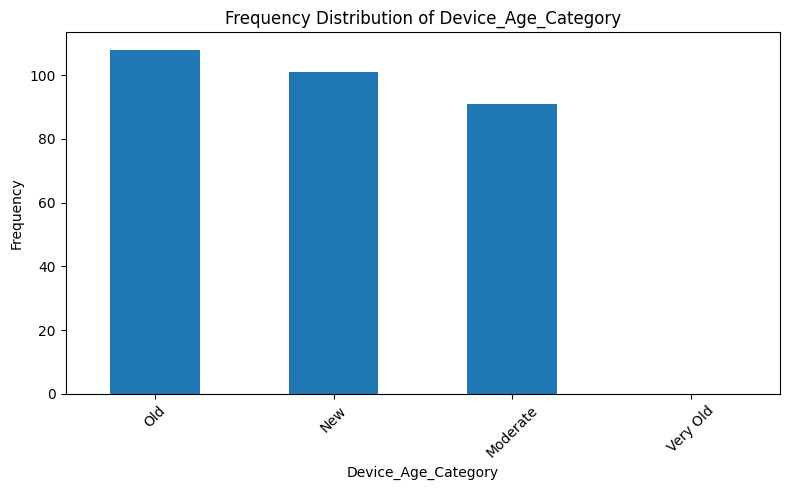

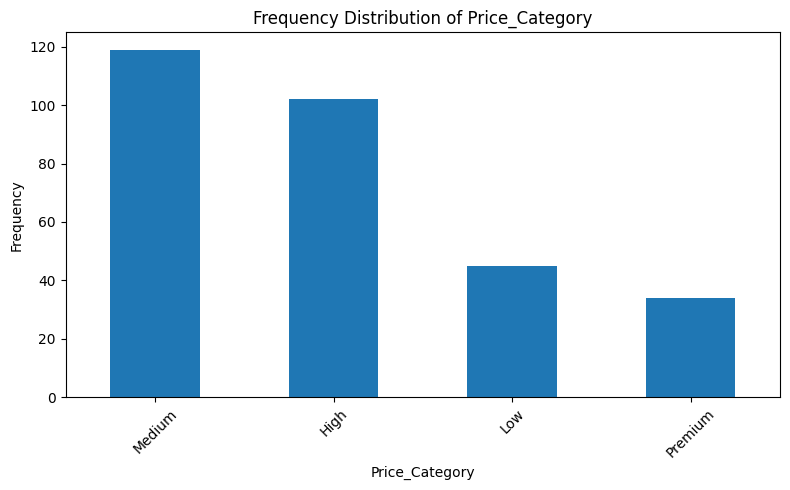

In [63]:
for column in categorical_columns:

    if df[column].nunique() <= 15:

        plt.figure(figsize=(8, 5))

        df[column].value_counts().plot(
            kind='bar'
        )

        plt.title(f'Frequency Distribution of {column}')
        plt.xlabel(column)
        plt.ylabel('Frequency')
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()

In [86]:
# outliers
numerical_columns = df.select_dtypes(
    include=['int64', 'float64']
).columns

print("Numerical columns:")
print(list(numerical_columns))

Numerical columns:
['Storage_GB', 'RAM_GB', 'Purchase_Year', 'Seller_Rating', 'Asking_Price_INR', 'Original_Price_INR', 'Age_Years', 'Battery_Health', 'Days_Listed', 'Views', 'Wishlist_Count', 'Final_Price_INR', 'Age', 'Discount_Amount_INR', 'Discount_Percentage', 'Price_Reduction_Percentage', 'Negotiation_Amount_INR', 'Wishlist_Conversion_Rate', 'Engagement_Score']


In [87]:
outlier_summary = []

for column in numerical_columns:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_limit) |
        (df[column] > upper_limit)
    ]

    outlier_summary.append({
        'Column': column,
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'Lower Limit': lower_limit,
        'Upper Limit': upper_limit,
        'Outlier Count': len(outliers),
        'Outlier %': round((len(outliers) / len(df)) * 100, 2)
    })

outlier_summary = pd.DataFrame(outlier_summary)

display(outlier_summary)

,Column,Q1,Q3,IQR,Lower Limit,Upper Limit,Outlier Count,Outlier %
0,Storage_GB,128.000000,512.000000,384.000000,-448.000000,1088.000000,0,0.00
1,RAM_GB,6.000000,16.000000,10.000000,-9.000000,31.000000,56,18.67
2,Purchase_Year,2019.000000,2024.000000,5.000000,2011.500000,2031.500000,0,0.00
3,Seller_Rating,3.900000,4.500000,0.600000,3.000000,5.400000,2,0.67
4,Asking_Price_INR,13345.000000,46329.250000,32984.250000,-36131.375000,95805.625000,6,2.00
5,Original_Price_INR,51999.750000,118729.000000,66729.250000,-48094.125000,218822.875000,0,0.00
6,Age_Years,2.000000,7.000000,5.000000,-5.500000,14.500000,0,0.00
7,Battery_Health,73.000000,87.000000,14.000000,52.000000,108.000000,7,2.33
8,Days_Listed,27.000000,34.000000,7.000000,16.500000,44.500000,4,1.33
9,Views,44.000000,216.250000,172.250000,-214.375000,474.625000,14,4.67


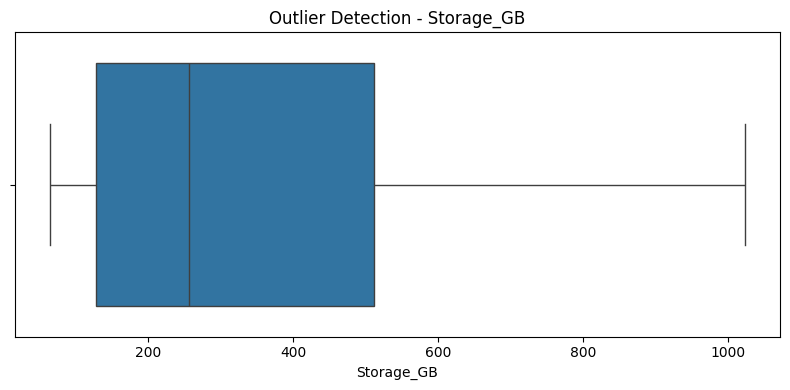

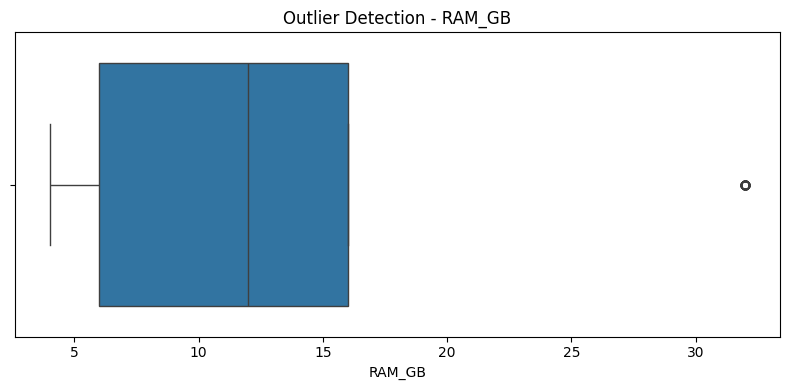

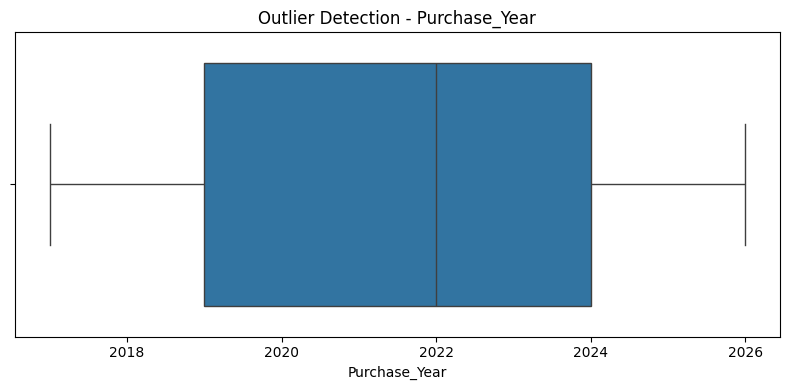

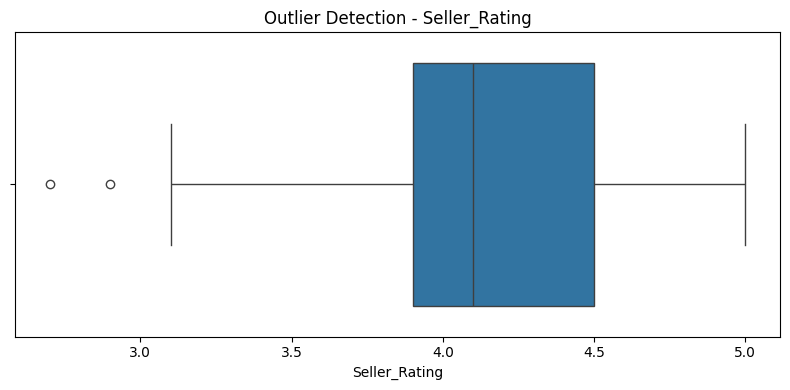

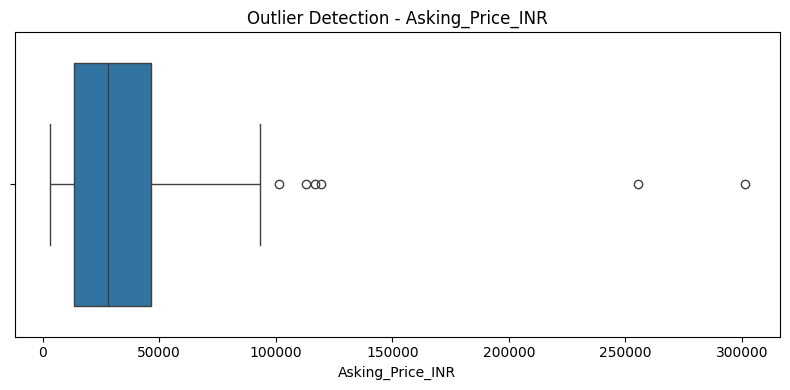

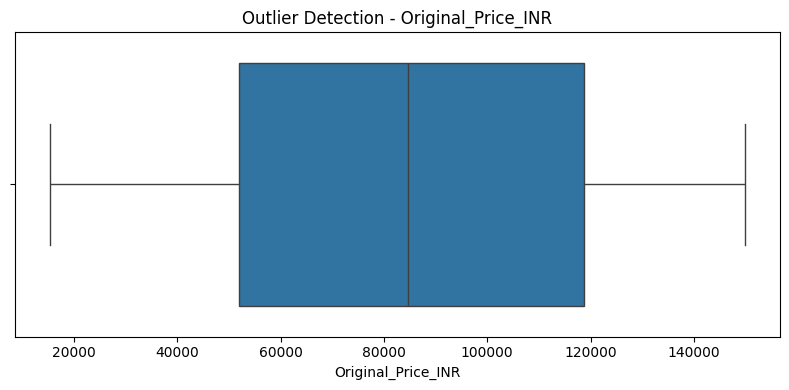

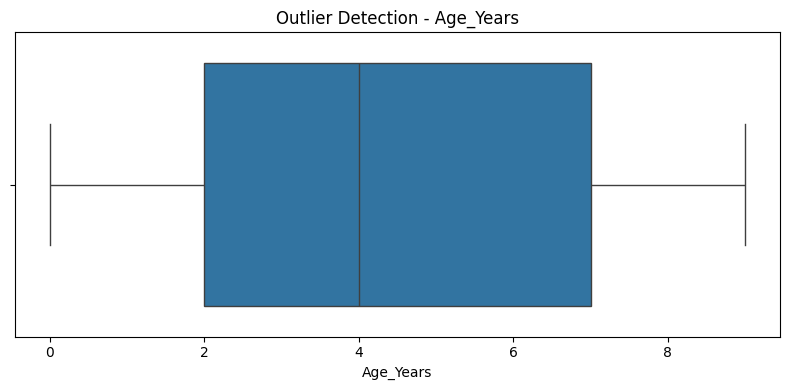

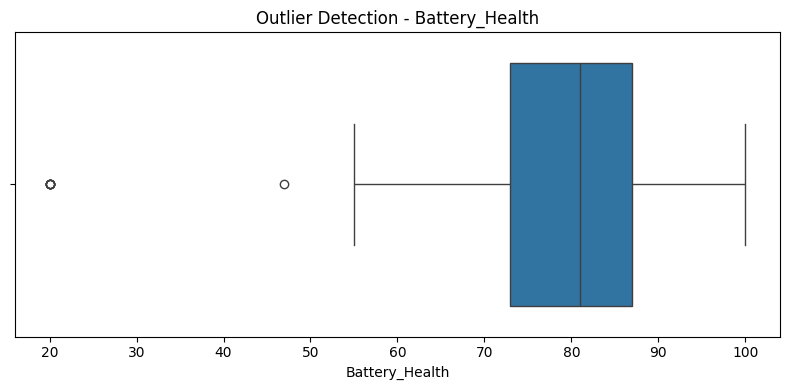

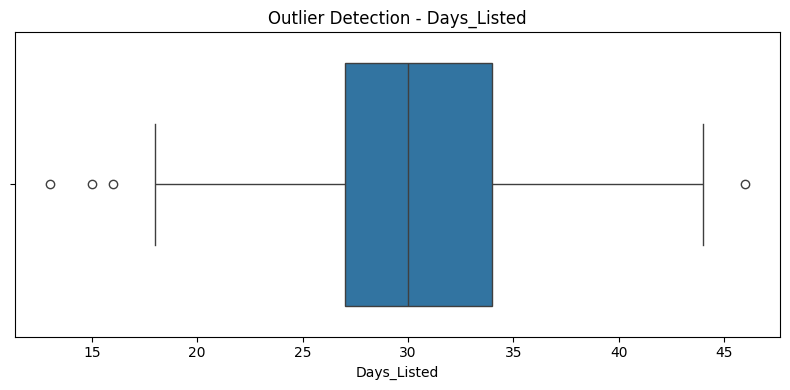

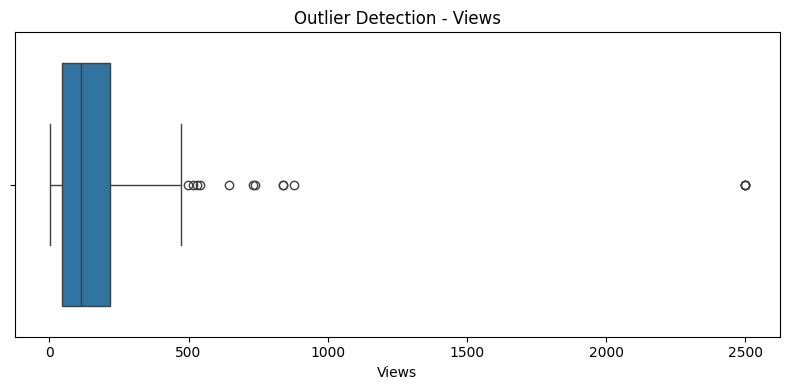

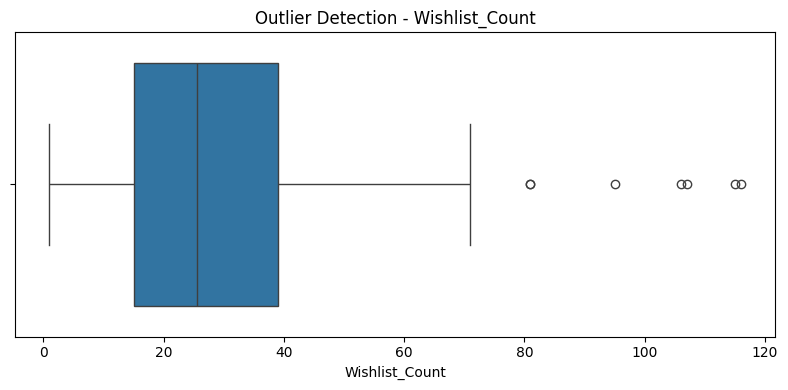

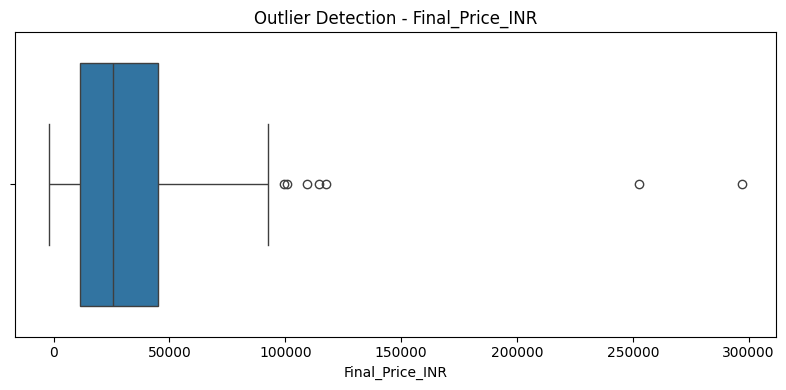

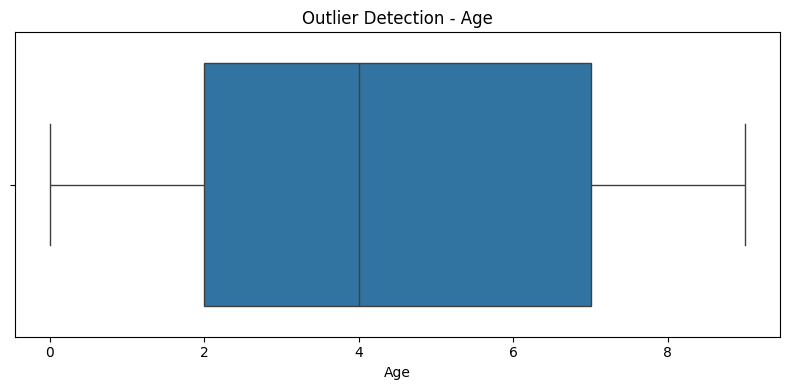

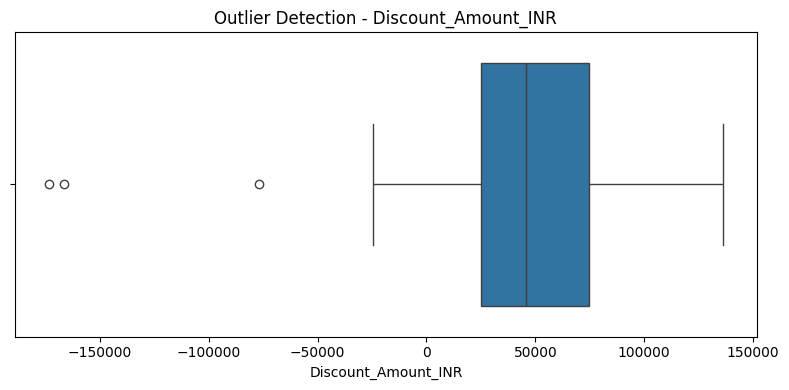

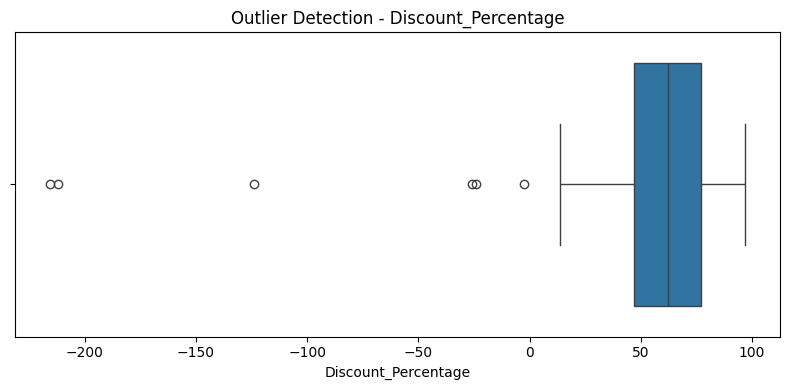

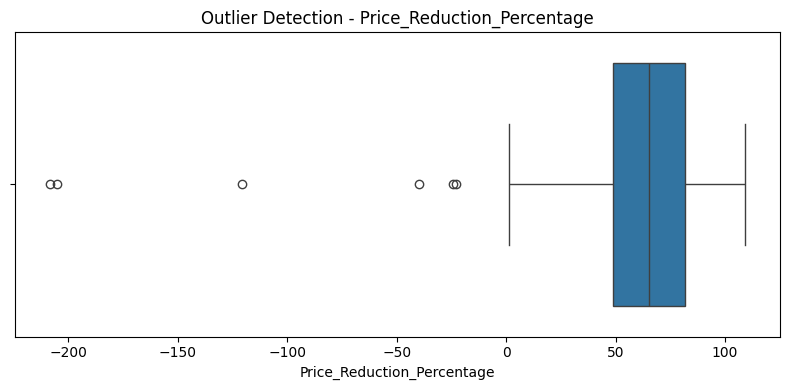

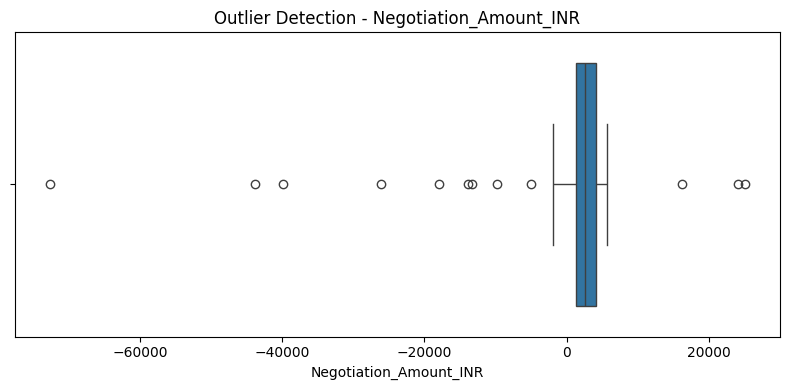

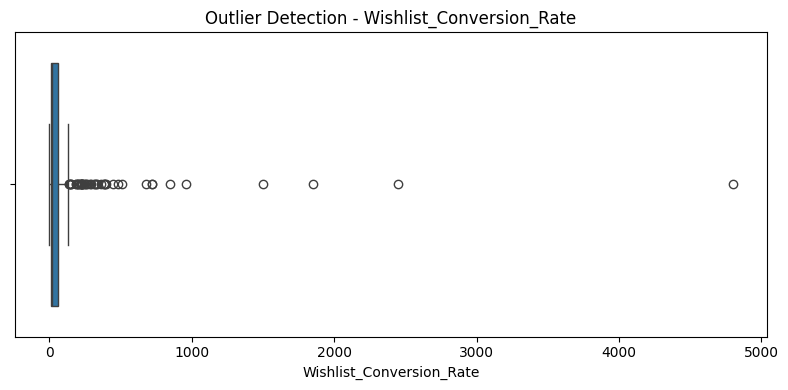

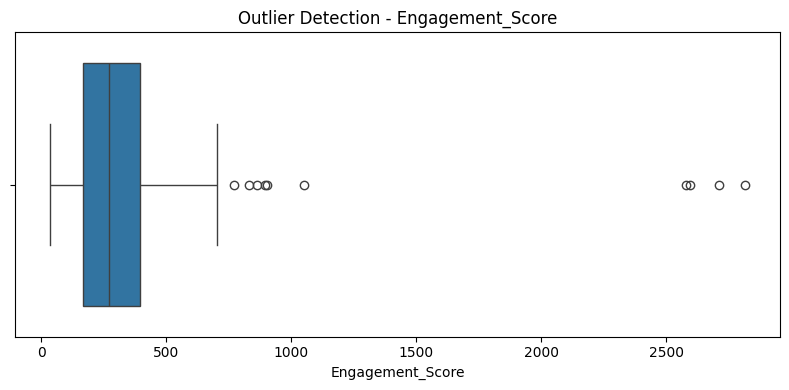

In [88]:
for column in numerical_columns:

    plt.figure(figsize=(8, 4))

    sns.boxplot(x=df[column])

    plt.title(f'Outlier Detection - {column}')
    plt.xlabel(column)
    plt.tight_layout()
    plt.show()

In [89]:
Q1 = df['Final_Price_INR'].quantile(0.25)
Q3 = df['Final_Price_INR'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

final_price_outliers = df[
    (df['Final_Price_INR'] < lower_limit) |
    (df['Final_Price_INR'] > upper_limit)
]

display(final_price_outliers)

,Listing_ID,Seller_ID,Product_Name,Brand,Category,Condition,Storage_GB,RAM_GB,Purchase_Year,Warranty_Status,...,Age,Favorite_Color,Discount_Amount_INR,Discount_Percentage,Price_Reduction_Percentage,Negotiation_Amount_INR,Wishlist_Conversion_Rate,Engagement_Score,Device_Age_Category,Price_Category
14,L0015,S165,Galaxy S,Lenovo,Phone,Excellent,1024.0,4,2017,Active,...,9,Black,38479.0,27.487552,28.927686,2016.0,200.000000,154.0,Old,Premium
51,L0052,S119,Galaxy S,Xiaomi,Laptop,Average,1024.0,32,2018,Expired,...,8,Yellow,-166650.0,-123.645942,-120.402879,4371.0,5.118110,319.0,Old,Premium
85,L0086,S177,Mi Pad,Xiaomi,Phone,Average,128.0,8,2017,Active,...,9,Black,-77142.0,-215.673227,-205.205771,3744.0,5.729167,247.0,Old,Premium
138,L0139,S148,ThinkPad,Xiaomi,Laptop,Poor,1024.0,6,2019,Expired,...,7,Blue,-24556.0,-25.885478,-24.151417,1645.0,128.571429,208.0,Old,Premium
201,L0202,S174,Mi Pad,Dell,Phone,Poor,128.0,16,2021,Active,...,5,Blue,19534.0,14.303078,16.092610,2444.0,22.994652,402.0,Moderate,Premium
225,L0226,S105,iPhone,OnePlus,Tablet,Excellent,1024.0,32,2026,Expired,...,0,White,-173575.0,-212.064753,-208.481368,2933.0,143.589744,319.0,New,Premium
228,L0229,S165,Galaxy S,Apple,Phone,Excellent,64.0,6,2024,Active,...,2,Yellow,114615.0,80.368412,29.386728,-72706.0,52.173913,249.0,New,Medium


In [90]:
# Create a copy before treatment
df_treated = df.copy()

for column in numerical_columns:

    Q1 = df_treated[column].quantile(0.25)
    Q3 = df_treated[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    df_treated[column] = df_treated[column].clip(
        lower=lower_limit,
        upper=upper_limit
    )

In [91]:
outlier_check_after = []

for column in numerical_columns:

    Q1 = df_treated[column].quantile(0.25)
    Q3 = df_treated[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    count = (
        (df_treated[column] < lower_limit) |
        (df_treated[column] > upper_limit)
    ).sum()

    outlier_check_after.append({
        'Column': column,
        'Remaining Outliers': count
    })

display(pd.DataFrame(outlier_check_after))

,Column,Remaining Outliers
0,Storage_GB,0
1,RAM_GB,0
2,Purchase_Year,0
3,Seller_Rating,0
4,Asking_Price_INR,0
5,Original_Price_INR,0
6,Age_Years,0
7,Battery_Health,0
8,Days_Listed,0
9,Views,0


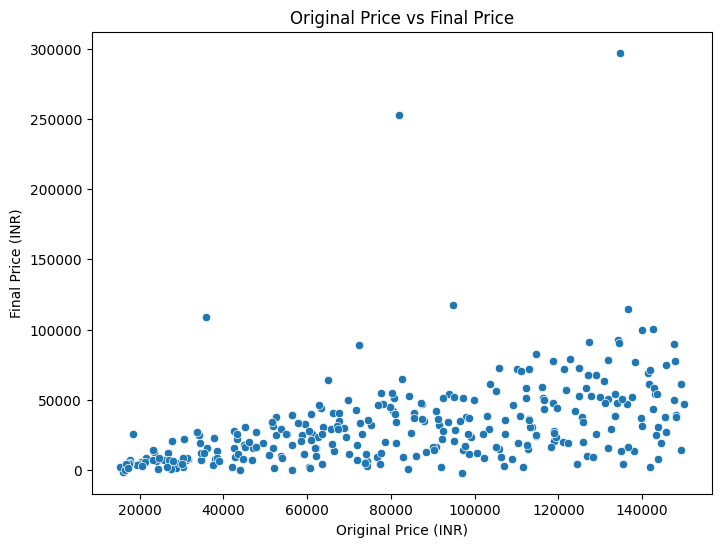

In [64]:
# BIVARIATE ANALYSIS
# NUMERICAL vs NUMERICAL
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x='Original_Price_INR',
    y='Final_Price_INR'
)

plt.title('Original Price vs Final Price')
plt.xlabel('Original Price (INR)')
plt.ylabel('Final Price (INR)')
plt.show()

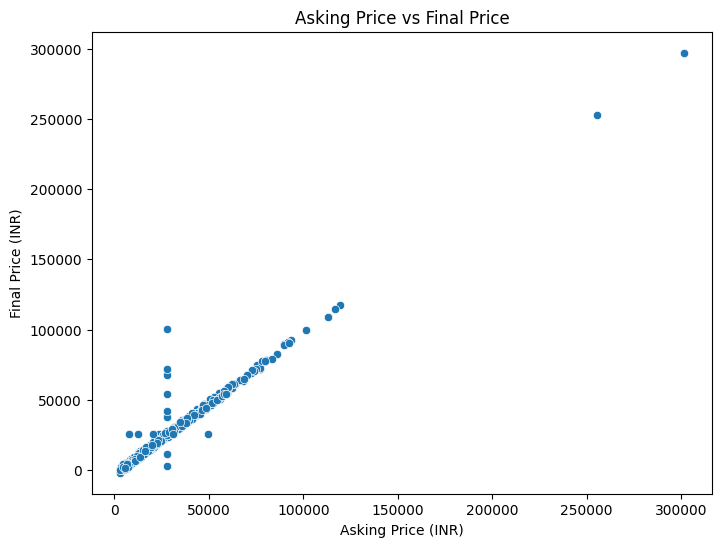

In [65]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x='Asking_Price_INR',
    y='Final_Price_INR'
)

plt.title('Asking Price vs Final Price')
plt.xlabel('Asking Price (INR)')
plt.ylabel('Final Price (INR)')
plt.show()

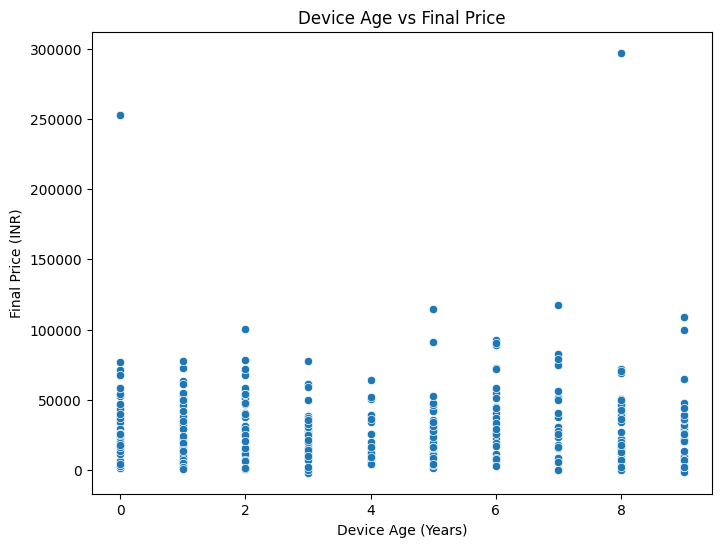

In [66]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x='Age_Years',
    y='Final_Price_INR'
)

plt.title('Device Age vs Final Price')
plt.xlabel('Device Age (Years)')
plt.ylabel('Final Price (INR)')
plt.show()

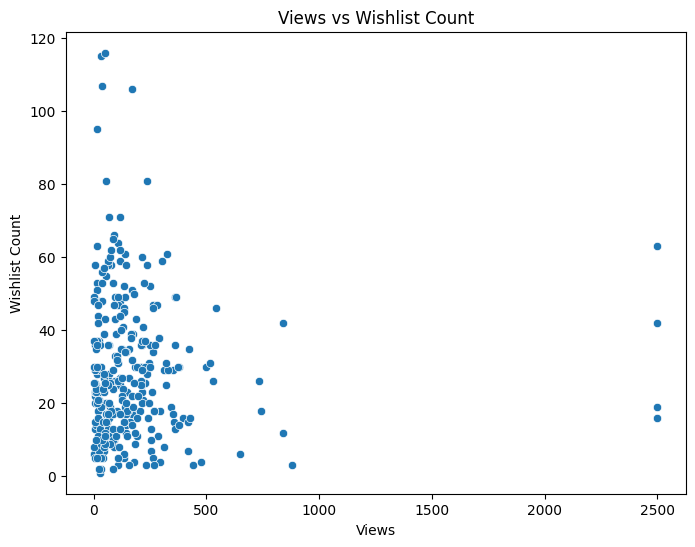

In [67]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x='Views',
    y='Wishlist_Count'
)

plt.title('Views vs Wishlist Count')
plt.xlabel('Views')
plt.ylabel('Wishlist Count')
plt.show()

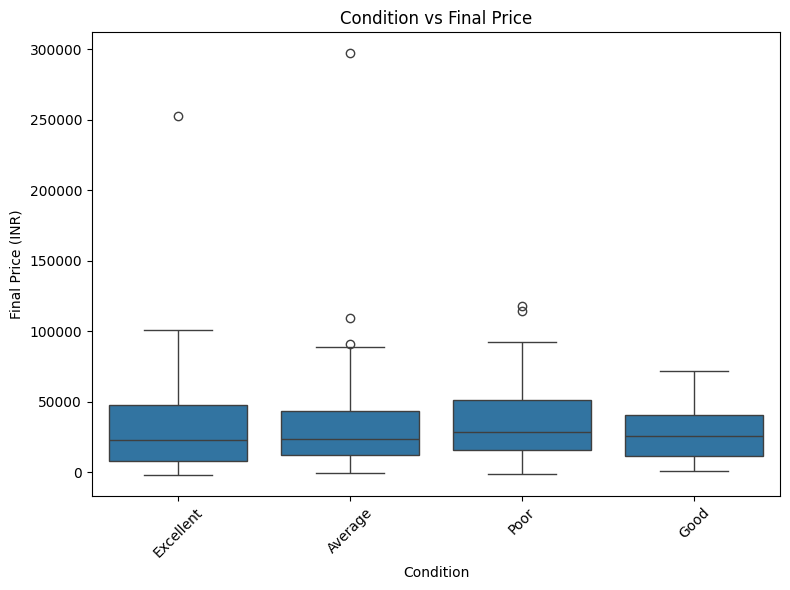

In [68]:
plt.figure(figsize=(8, 6))

sns.boxplot(
    data=df,
    x='Condition',
    y='Final_Price_INR'
)

plt.title('Condition vs Final Price')
plt.xlabel('Condition')
plt.ylabel('Final Price (INR)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

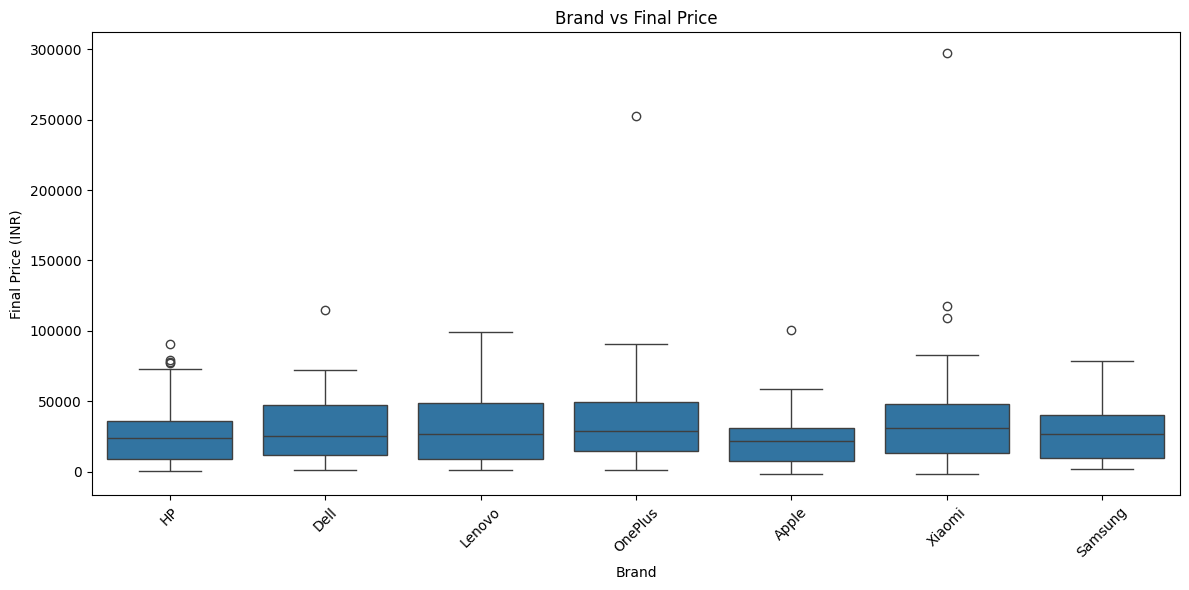

In [69]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x='Brand',
    y='Final_Price_INR'
)

plt.title('Brand vs Final Price')
plt.xlabel('Brand')
plt.ylabel('Final Price (INR)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

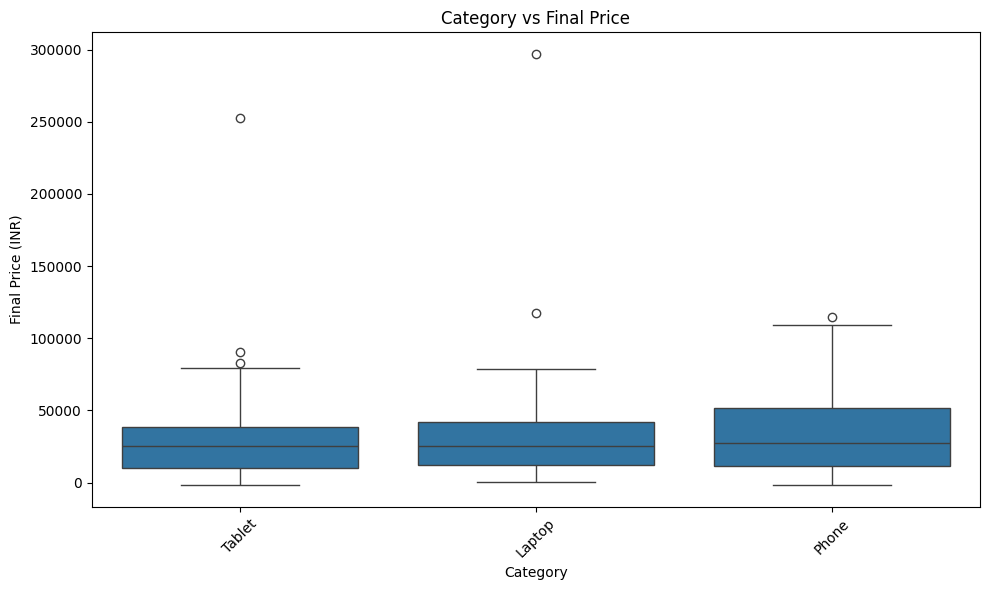

In [70]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='Category',
    y='Final_Price_INR'
)

plt.title('Category vs Final Price')
plt.xlabel('Category')
plt.ylabel('Final Price (INR)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

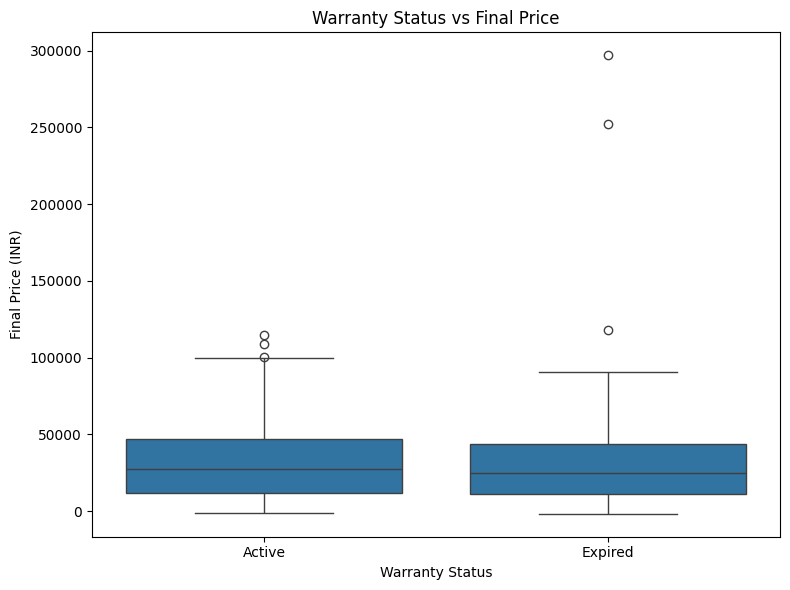

In [71]:
plt.figure(figsize=(8, 6))

sns.boxplot(
    data=df,
    x='Warranty_Status',
    y='Final_Price_INR'
)

plt.title('Warranty Status vs Final Price')
plt.xlabel('Warranty Status')
plt.ylabel('Final Price (INR)')
plt.tight_layout()
plt.show()

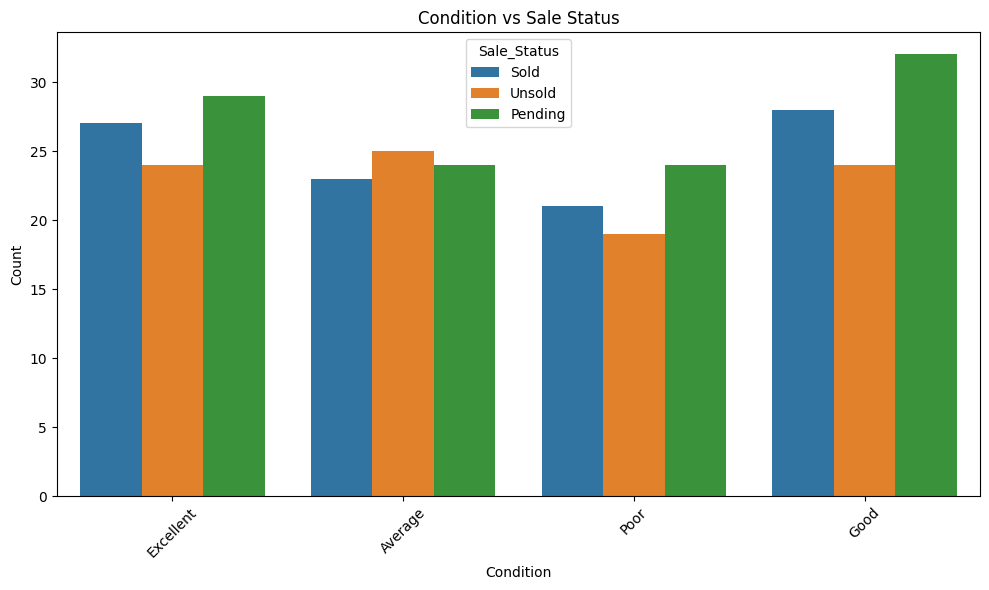

In [72]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x='Condition',
    hue='Sale_Status'
)

plt.title('Condition vs Sale Status')
plt.xlabel('Condition')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

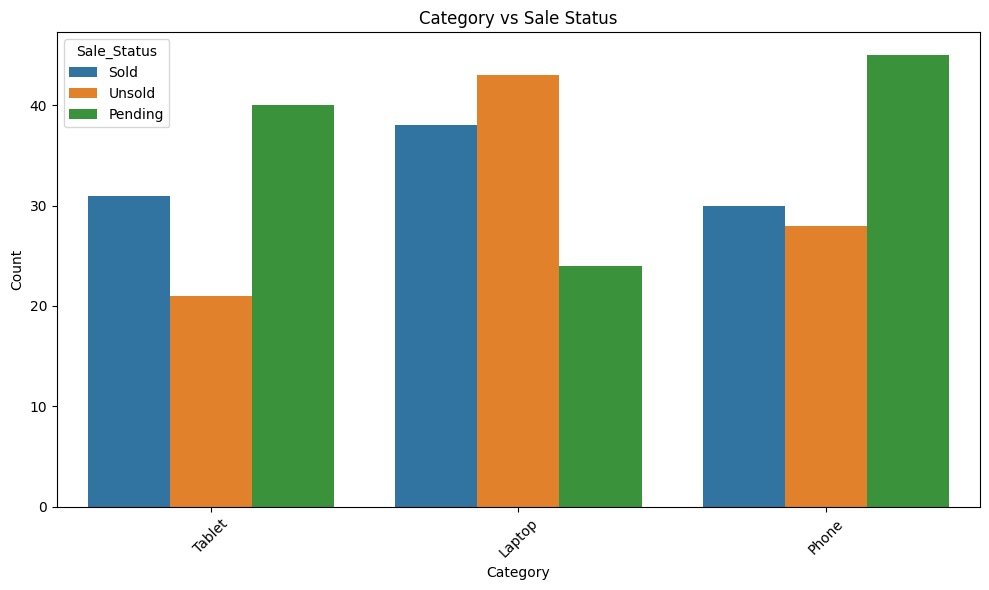

In [73]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x='Category',
    hue='Sale_Status'
)

plt.title('Category vs Sale Status')
plt.xlabel('Category')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

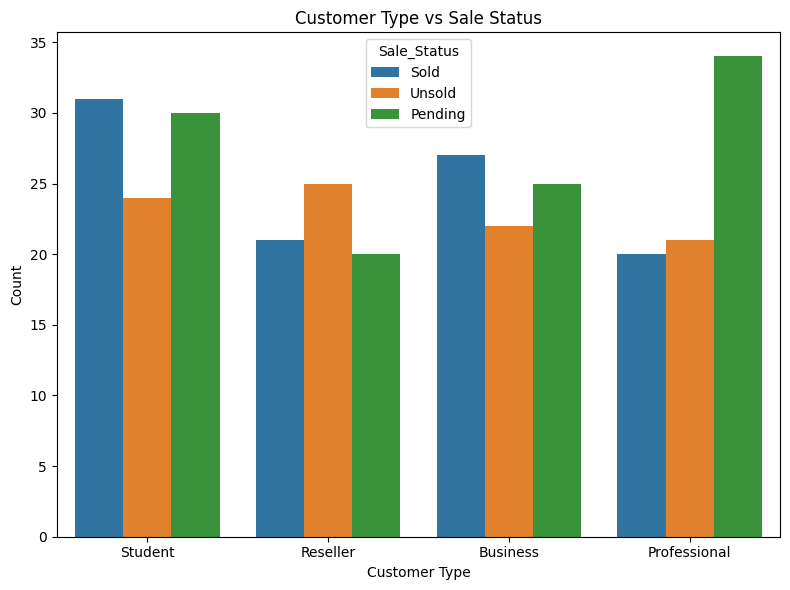

In [74]:
plt.figure(figsize=(8, 6))

sns.countplot(
    data=df,
    x='Customer_Type',
    hue='Sale_Status'
)

plt.title('Customer Type vs Sale Status')
plt.xlabel('Customer Type')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

In [75]:
important_columns = [
    'Storage_GB',
    'RAM_GB',
    'Seller_Rating',
    'Asking_Price_INR',
    'Original_Price_INR',
    'Age_Years',
    'Battery_Health',
    'Days_Listed',
    'Views',
    'Wishlist_Count',
    'Final_Price_INR'
]

corr = df[important_columns].corr()

display(corr)

,Storage_GB,RAM_GB,Seller_Rating,Asking_Price_INR,Original_Price_INR,Age_Years,Battery_Health,Days_Listed,Views,Wishlist_Count,Final_Price_INR
Storage_GB,1.000000,-0.028225,0.095333,0.124425,0.016560,0.034139,-0.046120,0.034291,0.000040,0.034540,0.108877
RAM_GB,-0.028225,1.000000,-0.047106,0.128429,0.039613,0.049099,0.003217,-0.000284,-0.111566,0.020523,0.126500
Seller_Rating,0.095333,-0.047106,1.000000,-0.013025,-0.020118,0.031081,0.022471,-0.036728,0.083783,0.053703,-0.016070
Asking_Price_INR,0.124425,0.128429,-0.013025,1.000000,0.432270,0.046990,-0.076377,0.024997,-0.005571,0.038814,0.976799
Original_Price_INR,0.016560,0.039613,-0.020118,0.432270,1.000000,-0.119038,-0.049488,-0.086630,-0.031734,-0.084006,0.450723
Age_Years,0.034139,0.049099,0.031081,0.046990,-0.119038,1.000000,-0.008443,0.101747,-0.057560,-0.024486,0.032358
Battery_Health,-0.046120,0.003217,0.022471,-0.076377,-0.049488,-0.008443,1.000000,0.086507,-0.126953,-0.003426,-0.053761
Days_Listed,0.034291,-0.000284,-0.036728,0.024997,-0.086630,0.101747,0.086507,1.000000,0.052187,0.014072,0.025721
Views,0.000040,-0.111566,0.083783,-0.005571,-0.031734,-0.057560,-0.126953,0.052187,1.000000,-0.011090,-0.034193
Wishlist_Count,0.034540,0.020523,0.053703,0.038814,-0.084006,-0.024486,-0.003426,0.014072,-0.011090,1.000000,0.024419


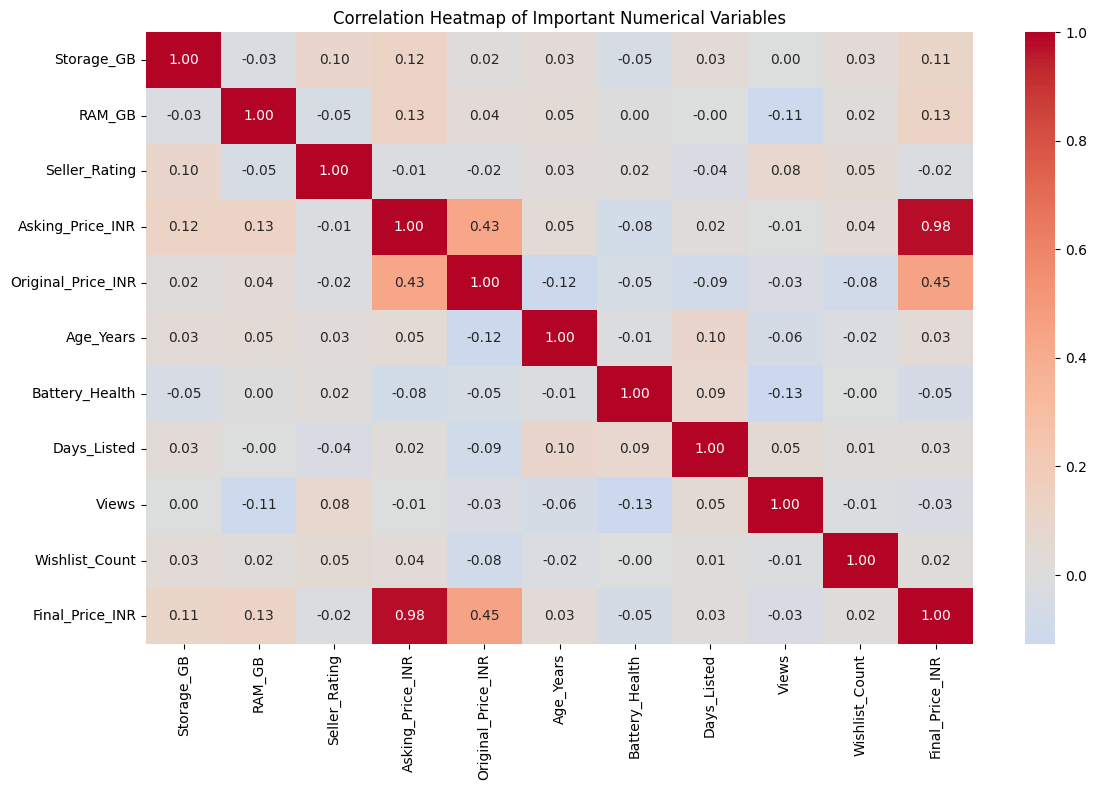

In [76]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0
)

plt.title('Correlation Heatmap of Important Numerical Variables')
plt.tight_layout()
plt.show()

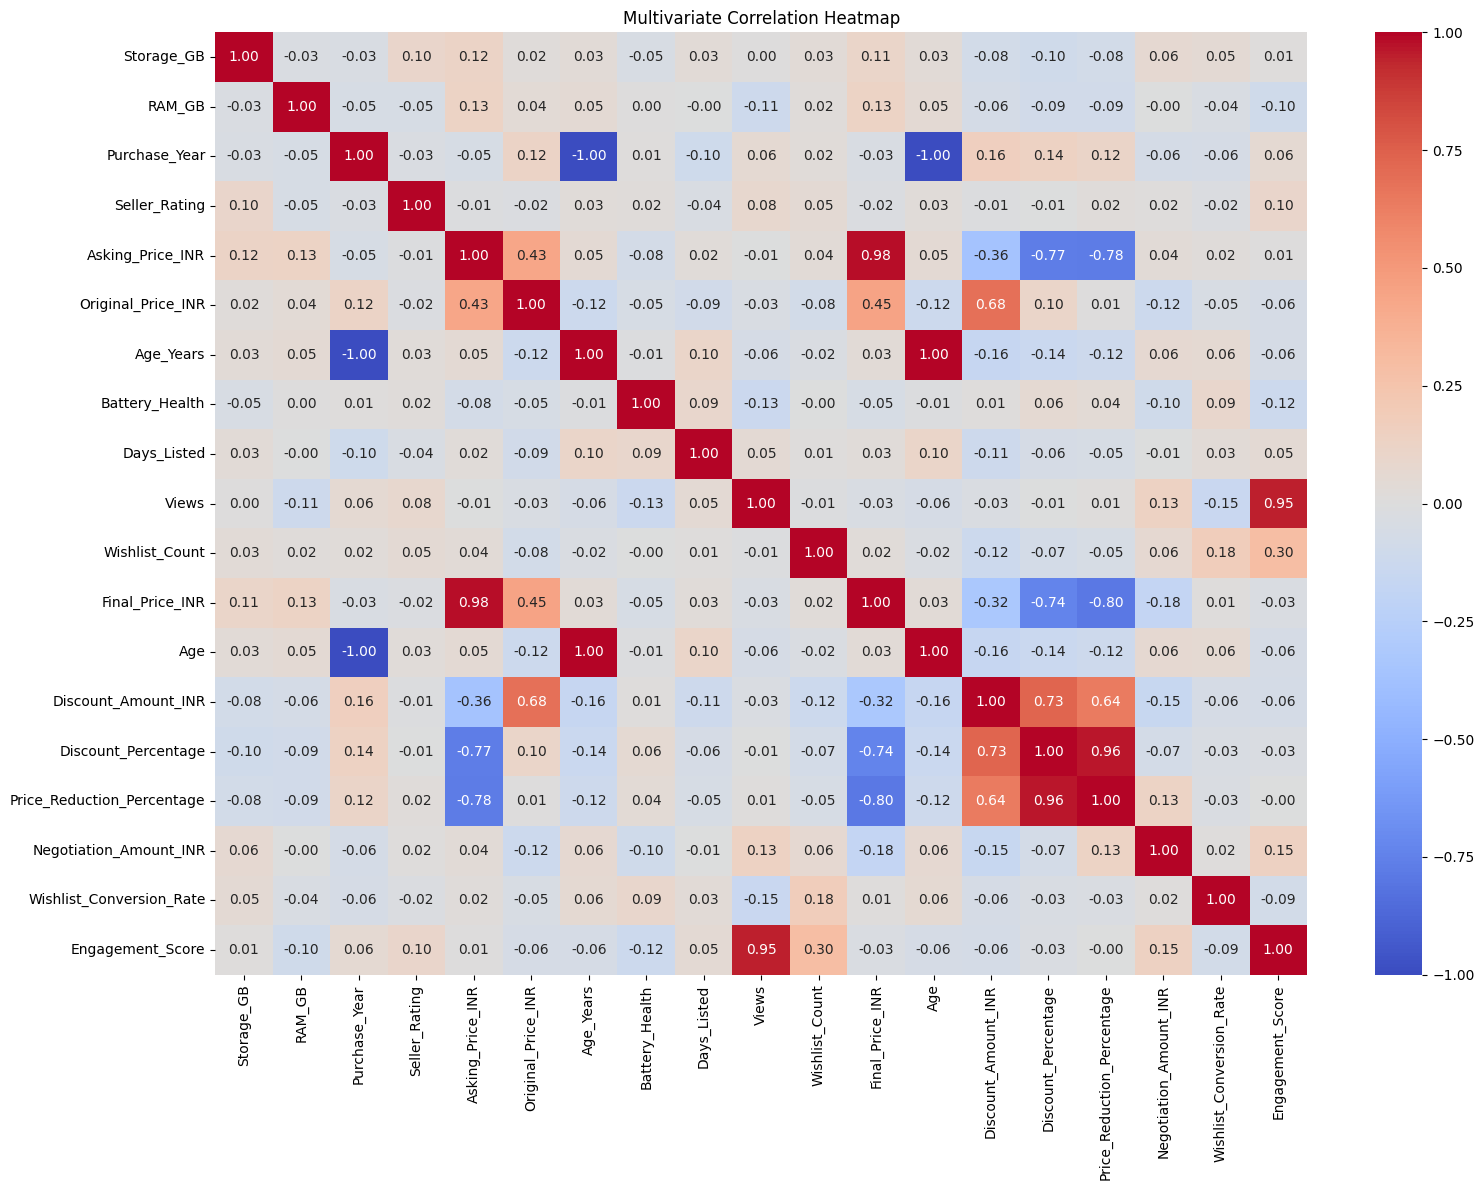

In [77]:
# multivariate analysis
plt.figure(figsize=(16, 12))

sns.heatmap(
    df.select_dtypes(include=np.number).corr(),
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0
)

plt.title('Multivariate Correlation Heatmap')
plt.tight_layout()
plt.show()

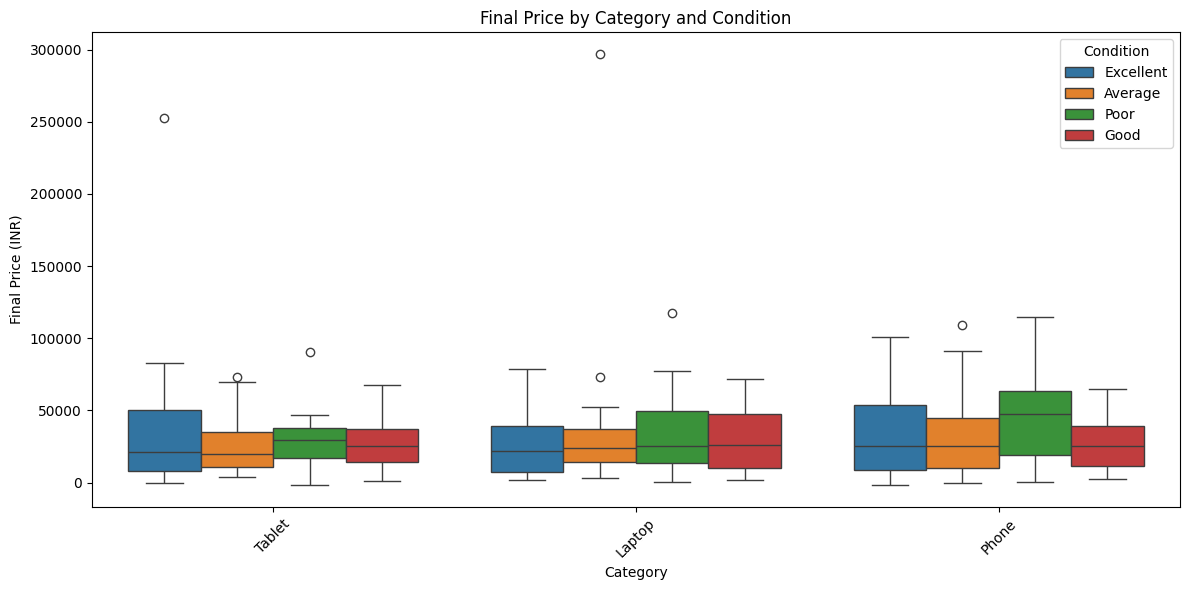

In [78]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x='Category',
    y='Final_Price_INR',
    hue='Condition'
)

plt.title('Final Price by Category and Condition')
plt.xlabel('Category')
plt.ylabel('Final Price (INR)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

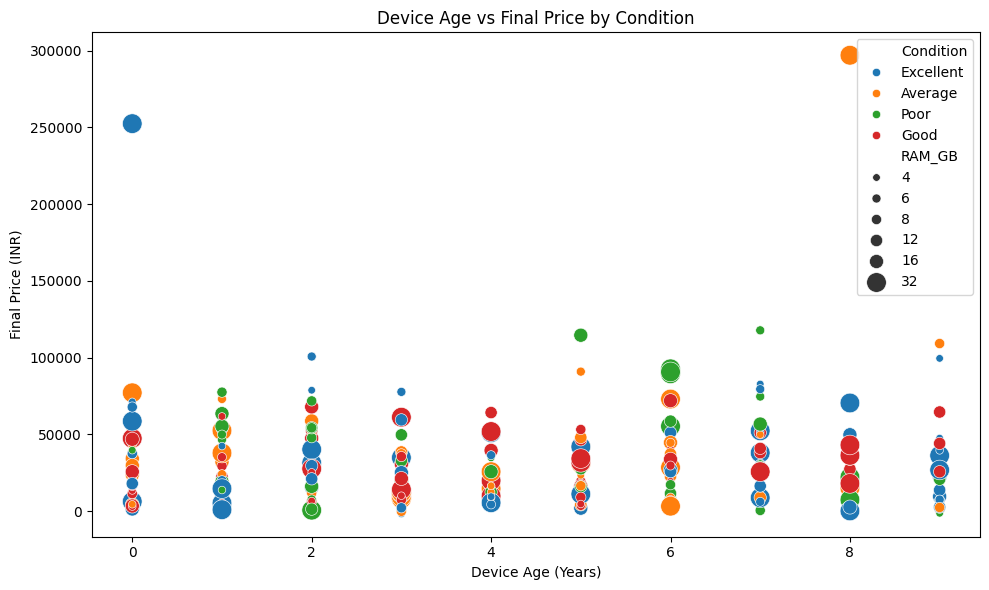

In [79]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Age_Years',
    y='Final_Price_INR',
    hue='Condition',
    size='RAM_GB',
    sizes=(30, 200)
)

plt.title('Device Age vs Final Price by Condition')
plt.xlabel('Device Age (Years)')
plt.ylabel('Final Price (INR)')
plt.tight_layout()
plt.show()

In [80]:
# feature engineering
df['Discount_Amount_INR'] = (
    df['Original_Price_INR'] - df['Asking_Price_INR']
)

display(df[['Original_Price_INR',
            'Asking_Price_INR',
            'Discount_Amount_INR']].head())

,Original_Price_INR,Asking_Price_INR,Discount_Amount_INR
0,21556,10658.0,10898.0
1,124974,76146.0,48828.0
2,84342,55115.0,29227.0
3,87869,36133.0,51736.0
4,72570,35385.0,37185.0


In [81]:
df['Discount_Percentage'] = (
    (df['Original_Price_INR'] - df['Asking_Price_INR'])
    / df['Original_Price_INR']
) * 100

In [30]:
display(
    df[['Original_Price_INR',
        'Asking_Price_INR',
        'Discount_Amount_INR',
        'Discount_Percentage']].head()
)

,Original_Price_INR,Asking_Price_INR,Discount_Amount_INR,Discount_Percentage
0,21556,10658.0,10898.0,50.556690
1,124974,76146.0,48828.0,39.070527
2,84342,55115.0,29227.0,34.652961
3,87869,36133.0,51736.0,58.878558
4,72570,35385.0,37185.0,51.240182


In [31]:
df['Price_Reduction_Percentage'] = (
    (df['Original_Price_INR'] - df['Final_Price_INR'])
    / df['Original_Price_INR']
) * 100

In [84]:
df['Negotiation_Amount_INR'] = (
    df['Asking_Price_INR'] - df['Final_Price_INR']
)

In [33]:
df['Wishlist_Conversion_Rate'] = (
    df['Wishlist_Count'] / df['Views'].replace(0, np.nan)
) * 100

In [34]:
df['Wishlist_Conversion_Rate'] = (
    df['Wishlist_Conversion_Rate'].fillna(0)
)

In [85]:
df['Engagement_Score'] = (
    df['Views'] + (df['Wishlist_Count'] * 5)
)

In [36]:
df['Device_Age_Category'] = pd.cut(
    df['Age_Years'],
    bins=[-1, 2, 5, 10, np.inf],
    labels=['New', 'Moderate', 'Old', 'Very Old']
)

In [37]:
display(
    df[['Age_Years', 'Device_Age_Category']].head(10)
)

,Age_Years,Device_Age_Category
0,8,Old
1,1,New
2,0,New
3,3,Moderate
4,1,New
5,2,New
6,7,Old
7,9,Old
8,8,Old
9,0,New


In [38]:
df['Price_Category'] = pd.cut(
    df['Asking_Price_INR'],
    bins=[-np.inf, 10000, 30000, 60000, np.inf],
    labels=['Low', 'Medium', 'High', 'Premium']
)

In [39]:
display(
    df[['Asking_Price_INR', 'Price_Category']].head(10)
)

,Asking_Price_INR,Price_Category
0,10658.0,Medium
1,76146.0,Premium
2,55115.0,High
3,36133.0,High
4,35385.0,High
5,25140.0,Medium
6,40307.0,High
7,5876.0,Low
8,76825.0,Premium
9,34708.0,High


In [12]:
print("Unique values in each column:")

for column in df.columns:
    print(column, ":", df[column].nunique())

Unique values in each column:
Listing_ID : 300
Seller_ID : 77
Product_Name : 6
Brand : 7
Category : 3
Condition : 4
Storage_GB : 5
RAM_GB : 6
Purchase_Year : 10
Warranty_Status : 2
City : 6
Seller_Rating : 22
Asking_Price_INR : 288
Original_Price_INR : 300
Age_Years : 10
Battery_Health : 47
Days_Listed : 31
Views : 199
Wishlist_Count : 72
Negotiation_Level : 3
Sale_Status : 3
Final_Price_INR : 291
Customer_Type : 4
Advertisement_Text : 1
Manufacture_Code : 296
Age : 10
Favorite_Color : 6


In [40]:
print("Shape after feature engineering:") #######
print(df.shape)

display(df.head())

Shape after feature engineering:
(300, 35)


,Listing_ID,Seller_ID,Product_Name,Brand,Category,Condition,Storage_GB,RAM_GB,Purchase_Year,Warranty_Status,...,Age,Favorite_Color,Discount_Amount_INR,Discount_Percentage,Price_Reduction_Percentage,Negotiation_Amount_INR,Wishlist_Conversion_Rate,Engagement_Score,Device_Age_Category,Price_Category
0,L0001,S113,Nord,HP,Tablet,Excellent,1024.0,12,2018,Active,...,8,Yellow,10898.0,50.556690,59.394136,1905.0,250.000000,108.0,Old,Medium
1,L0002,S100,iPhone,HP,Laptop,Average,256.0,6,2025,Active,...,1,Green,48828.0,39.070527,41.560645,3112.0,38.260870,335.0,New,Premium
2,L0003,S148,Galaxy S,Dell,Laptop,Average,1024.0,6,2026,Active,...,0,Red,29227.0,34.652961,37.462948,2370.0,23.478261,250.0,New,High
3,L0004,S145,iPhone,HP,Laptop,Excellent,1024.0,32,2023,Active,...,3,Green,51736.0,58.878558,60.401279,1338.0,15.909091,79.0,Moderate,High
4,L0005,S129,Galaxy S,Lenovo,Laptop,Poor,256.0,4,2025,Active,...,1,Yellow,37185.0,51.240182,53.639245,1741.0,26.027397,168.0,New,High


In [41]:
# label encoding
label_columns = [
    'Product_Name',
    'Brand',
    'Category',
    'Condition',
    'Warranty_Status',
    'City',
    'Negotiation_Level',
    'Sale_Status',
    'Customer_Type',
    'Favorite_Color'
]

In [42]:
df_encoded = df.copy()

In [43]:
label_encoders = {}

for column in label_columns:

    le = LabelEncoder()

    df_encoded[column] = le.fit_transform(
        df_encoded[column].astype(str)
    )

    label_encoders[column] = le

In [44]:
display(df_encoded.head())

,Listing_ID,Seller_ID,Product_Name,Brand,Category,Condition,Storage_GB,RAM_GB,Purchase_Year,Warranty_Status,...,Age,Favorite_Color,Discount_Amount_INR,Discount_Percentage,Price_Reduction_Percentage,Negotiation_Amount_INR,Wishlist_Conversion_Rate,Engagement_Score,Device_Age_Category,Price_Category
0,L0001,S113,3,2,2,1,1024.0,12,2018,0,...,8,5,10898.0,50.556690,59.394136,1905.0,250.000000,108.0,Old,Medium
1,L0002,S100,5,2,0,0,256.0,6,2025,0,...,1,2,48828.0,39.070527,41.560645,3112.0,38.260870,335.0,New,Premium
2,L0003,S148,0,1,0,0,1024.0,6,2026,0,...,0,3,29227.0,34.652961,37.462948,2370.0,23.478261,250.0,New,High
3,L0004,S145,5,2,0,1,1024.0,32,2023,0,...,3,2,51736.0,58.878558,60.401279,1338.0,15.909091,79.0,Moderate,High
4,L0005,S129,0,3,0,3,256.0,4,2025,0,...,1,5,37185.0,51.240182,53.639245,1741.0,26.027397,168.0,New,High


In [45]:
for column in label_columns:
    print(f"\n{column}")
    print(df_encoded[column].value_counts().sort_index())


Product_Name
Product_Name
0    51
1    49
2    55
3    56
4    40
5    49
Name: count, dtype: int64

Brand
Brand
0    34
1    39
2    56
3    39
4    46
5    33
6    53
Name: count, dtype: int64

Category
Category
0    105
1    103
2     92
Name: count, dtype: int64

Condition
Condition
0    72
1    80
2    84
3    64
Name: count, dtype: int64

Warranty_Status
Warranty_Status
0    152
1    148
Name: count, dtype: int64

City
City
0    62
1    52
2    45
3    44
4    45
5    52
Name: count, dtype: int64

Negotiation_Level
Negotiation_Level
0    103
1     94
2    103
Name: count, dtype: int64

Sale_Status
Sale_Status
0    109
1     99
2     92
Name: count, dtype: int64

Customer_Type
Customer_Type
0    74
1    75
2    66
3    85
Name: count, dtype: int64

Favorite_Color
Favorite_Color
0    31
1    61
2    59
3    46
4    54
5    49
Name: count, dtype: int64


In [46]:
for column, le in label_encoders.items():
    print("\nColumn:", column)
    print(dict(zip(le.classes_, le.transform(le.classes_))))


Column: Product_Name
{'Galaxy S': np.int64(0), 'Inspiron': np.int64(1), 'Mi Pad': np.int64(2), 'Nord': np.int64(3), 'ThinkPad': np.int64(4), 'iPhone': np.int64(5)}

Column: Brand
{'Apple': np.int64(0), 'Dell': np.int64(1), 'HP': np.int64(2), 'Lenovo': np.int64(3), 'OnePlus': np.int64(4), 'Samsung': np.int64(5), 'Xiaomi': np.int64(6)}

Column: Category
{'Laptop': np.int64(0), 'Phone': np.int64(1), 'Tablet': np.int64(2)}

Column: Condition
{'Average': np.int64(0), 'Excellent': np.int64(1), 'Good': np.int64(2), 'Poor': np.int64(3)}

Column: Warranty_Status
{'Active': np.int64(0), 'Expired': np.int64(1)}

Column: City
{'Bengaluru': np.int64(0), 'Delhi': np.int64(1), 'Hyderabad': np.int64(2), 'Mumbai': np.int64(3), 'Nagpur': np.int64(4), 'Pune': np.int64(5)}

Column: Negotiation_Level
{'High': np.int64(0), 'Low': np.int64(1), 'Medium': np.int64(2)}

Column: Sale_Status
{'Pending': np.int64(0), 'Sold': np.int64(1), 'Unsold': np.int64(2)}

Column: Customer_Type
{'Business': np.int64(0), 'Pro

In [47]:
# correlation analysis
correlation_matrix = df_encoded.corr(numeric_only=True)

display(correlation_matrix)

,Product_Name,Brand,Category,Condition,Storage_GB,RAM_GB,Purchase_Year,Warranty_Status,City,Seller_Rating,...,Final_Price_INR,Customer_Type,Age,Favorite_Color,Discount_Amount_INR,Discount_Percentage,Price_Reduction_Percentage,Negotiation_Amount_INR,Wishlist_Conversion_Rate,Engagement_Score
Product_Name,1.000000,0.069746,0.033538,-0.004784,-0.067419,0.026292,-0.104879,-0.083561,0.042091,0.025079,...,-0.008490,0.039290,0.104879,0.046153,0.016918,-0.010717,-0.016194,0.029012,-0.022473,-0.087574
Brand,0.069746,1.000000,-0.040659,0.109440,0.032361,-0.053701,-0.054564,0.063275,0.050045,-0.009289,...,0.115944,0.057724,0.054564,0.053574,-0.036602,-0.122128,-0.105877,0.075047,0.018425,-0.078631
Category,0.033538,-0.040659,1.000000,-0.072554,-0.046083,0.040771,-0.047142,0.069321,0.101786,0.004140,...,-0.014218,0.014477,0.047142,-0.110416,0.053519,0.033109,0.018621,-0.053059,-0.042027,-0.052356
Condition,-0.004784,0.109440,-0.072554,1.000000,0.019486,-0.095286,-0.014221,-0.074841,-0.075330,-0.008589,...,-0.002779,0.060724,0.014221,0.026754,-0.000487,-0.003367,-0.000681,-0.007466,-0.052697,-0.000529
Storage_GB,-0.067419,0.032361,-0.046083,0.019486,1.000000,-0.028225,-0.034139,0.029785,-0.078094,0.095333,...,0.108877,-0.073214,0.034139,0.008450,-0.083418,-0.098449,-0.084796,0.063533,0.051374,0.010614
RAM_GB,0.026292,-0.053701,0.040771,-0.095286,-0.028225,1.000000,-0.049099,0.034891,-0.035951,-0.047106,...,0.126500,-0.051254,0.049099,0.049181,-0.062813,-0.089311,-0.089980,-0.000313,-0.037799,-0.100304
Purchase_Year,-0.104879,-0.054564,-0.047142,-0.014221,-0.034139,-0.049099,1.000000,0.108429,-0.058700,-0.031081,...,-0.032358,0.009728,-1.000000,0.057642,0.161077,0.138693,0.115930,-0.064872,-0.059926,0.062488
Warranty_Status,-0.083561,0.063275,0.069321,-0.074841,0.029785,0.034891,0.108429,1.000000,-0.000900,0.055828,...,0.008663,-0.098623,-0.108429,-0.069415,0.005753,-0.004467,-0.009899,-0.001896,0.043969,0.006614
City,0.042091,0.050045,0.101786,-0.075330,-0.078094,-0.035951,-0.058700,-0.000900,1.000000,-0.041479,...,0.069187,-0.009111,0.058700,0.023632,-0.011113,-0.050380,-0.055669,-0.022974,-0.011932,0.039529
Seller_Rating,0.025079,-0.009289,0.004140,-0.008589,0.095333,-0.047106,-0.031081,0.055828,-0.041479,1.000000,...,-0.016070,0.060472,0.031081,0.036396,-0.010280,-0.005207,0.017141,0.015155,-0.020891,0.096487


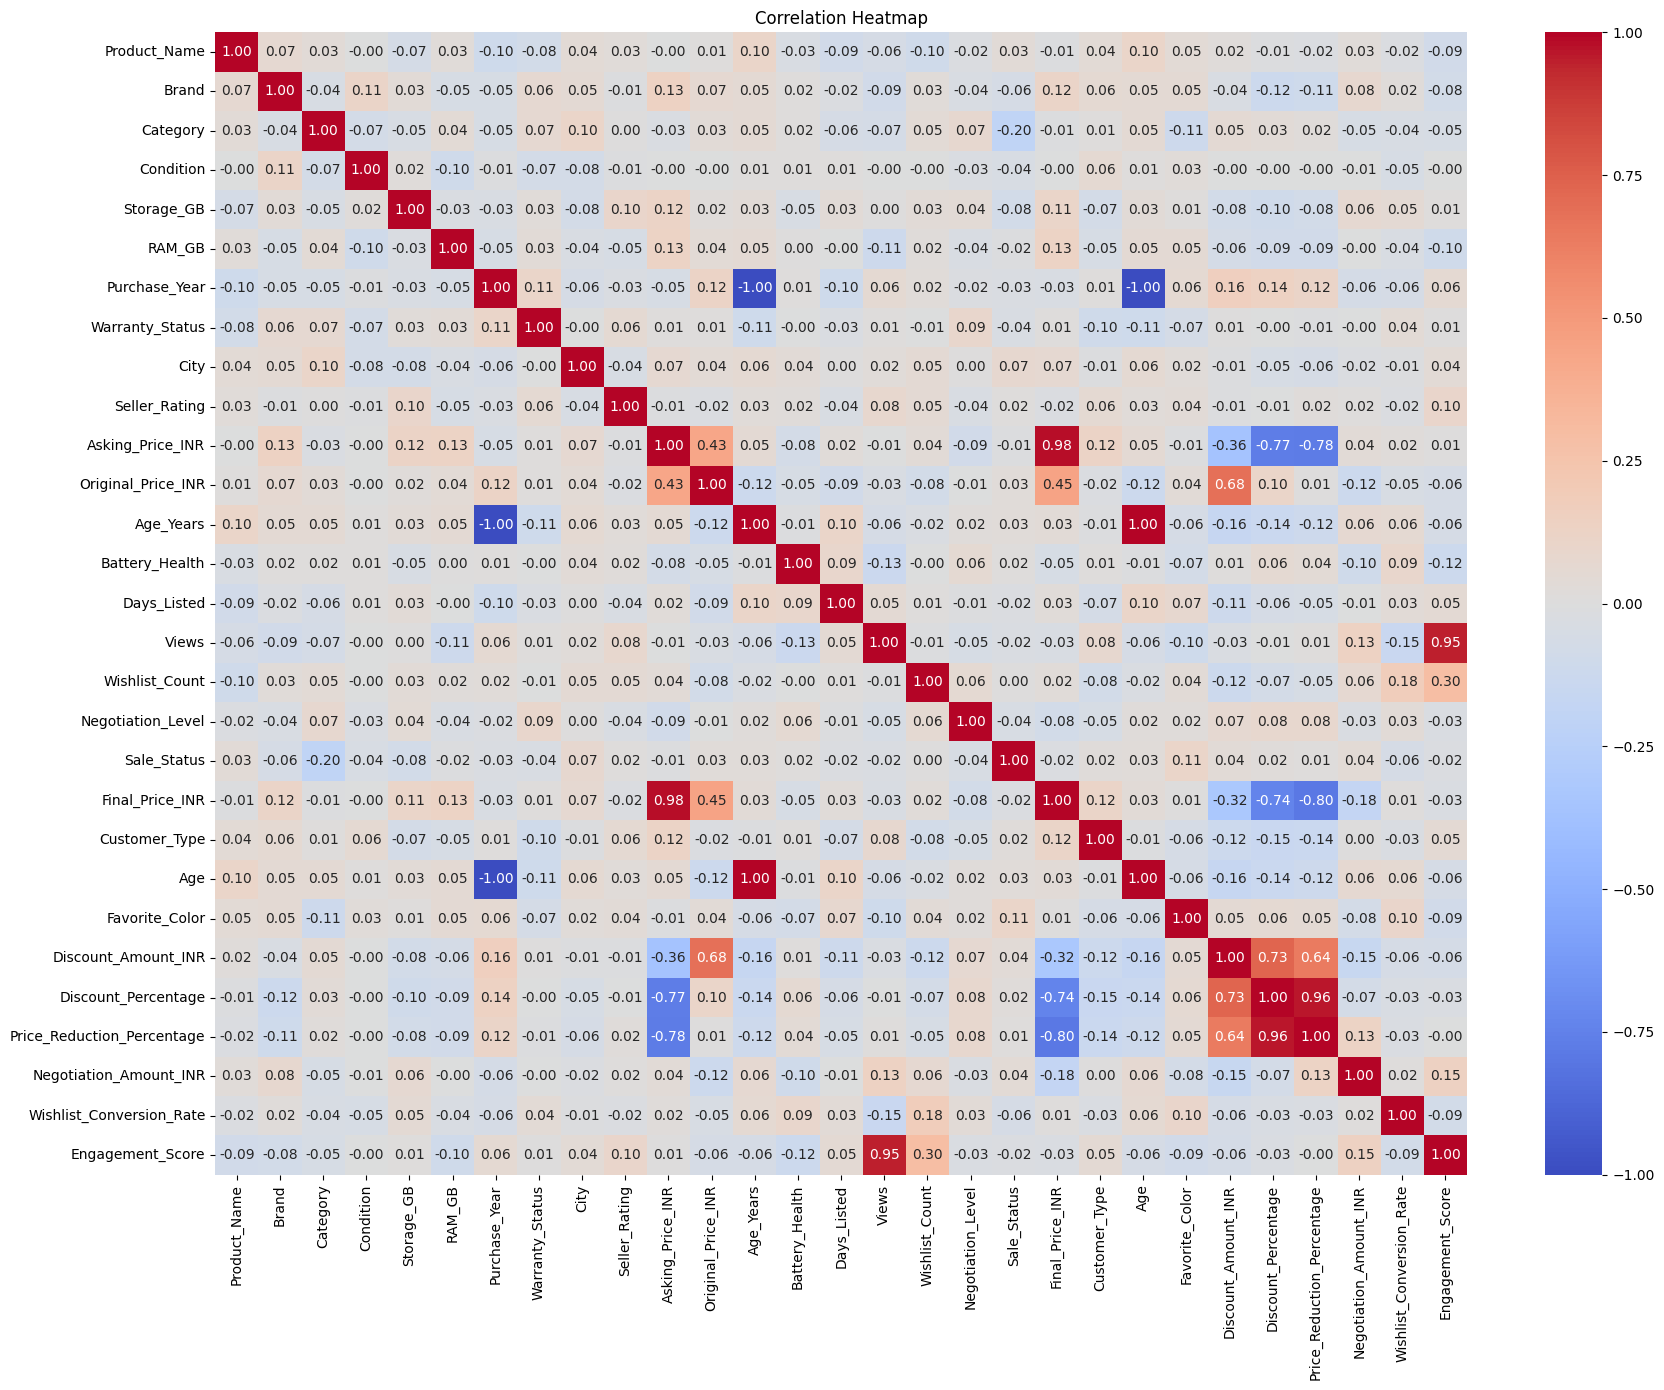

In [48]:
plt.figure(figsize=(18, 14))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [49]:
final_price_corr = (
    correlation_matrix['Final_Price_INR']
    .sort_values(ascending=False)
)

print("Correlation with Final Price:")
display(final_price_corr)

Correlation with Final Price:


,Final_Price_INR
Final_Price_INR,1.000000
Asking_Price_INR,0.976799
Original_Price_INR,0.450723
RAM_GB,0.126500
Customer_Type,0.116813
Brand,0.115944
Storage_GB,0.108877
City,0.069187
Age,0.032358
Age_Years,0.032358


In [50]:
asking_price_corr = (
    correlation_matrix['Asking_Price_INR']
    .sort_values(ascending=False)
)

print("Correlation with Asking Price:")
display(asking_price_corr)

Correlation with Asking Price:


,Asking_Price_INR
Asking_Price_INR,1.000000
Final_Price_INR,0.976799
Original_Price_INR,0.432270
Brand,0.134111
RAM_GB,0.128429
Storage_GB,0.124425
Customer_Type,0.118919
City,0.065279
Age_Years,0.046990
Age,0.046990


In [51]:
# min- max scaling
scaling_columns = [
    'Storage_GB',
    'RAM_GB',
    'Purchase_Year',
    'Seller_Rating',
    'Asking_Price_INR',
    'Original_Price_INR',
    'Age_Years',
    'Battery_Health',
    'Days_Listed',
    'Views',
    'Wishlist_Count',
    'Final_Price_INR',
    'Age',
    'Discount_Amount_INR',
    'Discount_Percentage',
    'Price_Reduction_Percentage',
    'Negotiation_Amount_INR',
    'Wishlist_Conversion_Rate',
    'Engagement_Score'
]

In [52]:
scaler = MinMaxScaler()

df_scaled = df_encoded.copy()

df_scaled[scaling_columns] = scaler.fit_transform(
    df_scaled[scaling_columns]
)

In [53]:
display(
    df_scaled[
        scaling_columns
    ].head()
)

,Storage_GB,RAM_GB,Purchase_Year,Seller_Rating,Asking_Price_INR,Original_Price_INR,Age_Years,Battery_Health,Days_Listed,Views,Wishlist_Count,Final_Price_INR,Age,Discount_Amount_INR,Discount_Percentage,Price_Reduction_Percentage,Negotiation_Amount_INR,Wishlist_Conversion_Rate,Engagement_Score
0,1.0,0.285714,0.111111,0.956522,0.025661,0.046368,0.888889,0.7375,0.696970,0.002801,0.165217,0.035324,0.888889,0.595383,0.851723,0.843162,0.762855,0.052016,0.026959
1,0.2,0.071429,0.888889,0.347826,0.245103,0.814601,0.111111,0.6500,0.393939,0.045618,0.373913,0.250409,0.111111,0.717802,0.814976,0.787029,0.775196,0.007901,0.108555
2,1.0,0.071429,1.000000,0.521739,0.174631,0.512769,0.000000,0.7000,0.606061,0.045618,0.226087,0.182522,0.000000,0.654540,0.800844,0.774131,0.767609,0.004821,0.078001
3,1.0,1.000000,0.666667,0.608696,0.111024,0.538970,0.333333,0.7625,0.545455,0.017207,0.052174,0.122461,0.333333,0.727187,0.878346,0.846332,0.757057,0.003244,0.016535
4,0.2,0.000000,0.888889,0.565217,0.108518,0.425322,0.111111,0.7500,0.393939,0.028812,0.156522,0.118610,0.111111,0.680224,0.853910,0.825048,0.761178,0.005352,0.048526


In [54]:
scaling_check = pd.DataFrame({
    'Minimum': df_scaled[scaling_columns].min(),
    'Maximum': df_scaled[scaling_columns].max()
})

display(scaling_check)

,Minimum,Maximum
Storage_GB,0.0,1.0
RAM_GB,0.0,1.0
Purchase_Year,0.0,1.0
Seller_Rating,0.0,1.0
Asking_Price_INR,0.0,1.0
Original_Price_INR,0.0,1.0
Age_Years,0.0,1.0
Battery_Health,0.0,1.0
Days_Listed,0.0,1.0
Views,0.0,1.0


In [55]:
print("Final Dataset Shape:")
print(df_scaled.shape)

print("\nMissing Values:")
print(df_scaled.isnull().sum().sum())

print("\nDuplicate Rows:")
print(df_scaled.duplicated().sum())

print("\nFinal Data Types:")
display(df_scaled.dtypes)

print("\nFinal Dataset:")
display(df_scaled.head())

Final Dataset Shape:
(300, 35)

Missing Values:
0

Duplicate Rows:
0

Final Data Types:


,0
Listing_ID,object
Seller_ID,object
Product_Name,int64
Brand,int64
Category,int64
Condition,int64
Storage_GB,float64
RAM_GB,float64
Purchase_Year,float64
Warranty_Status,int64



Final Dataset:


,Listing_ID,Seller_ID,Product_Name,Brand,Category,Condition,Storage_GB,RAM_GB,Purchase_Year,Warranty_Status,...,Age,Favorite_Color,Discount_Amount_INR,Discount_Percentage,Price_Reduction_Percentage,Negotiation_Amount_INR,Wishlist_Conversion_Rate,Engagement_Score,Device_Age_Category,Price_Category
0,L0001,S113,3,2,2,1,1.0,0.285714,0.111111,0,...,0.888889,5,0.595383,0.851723,0.843162,0.762855,0.052016,0.026959,Old,Medium
1,L0002,S100,5,2,0,0,0.2,0.071429,0.888889,0,...,0.111111,2,0.717802,0.814976,0.787029,0.775196,0.007901,0.108555,New,Premium
2,L0003,S148,0,1,0,0,1.0,0.071429,1.000000,0,...,0.000000,3,0.654540,0.800844,0.774131,0.767609,0.004821,0.078001,New,High
3,L0004,S145,5,2,0,1,1.0,1.000000,0.666667,0,...,0.333333,2,0.727187,0.878346,0.846332,0.757057,0.003244,0.016535,Moderate,High
4,L0005,S129,0,3,0,3,0.2,0.000000,0.888889,0,...,0.111111,5,0.680224,0.853910,0.825048,0.761178,0.005352,0.048526,New,High


In [94]:
# Save as CSV
df_scaled.to_csv('EDA_Preprocessed.csv',index=False)
print("Processed dataset saved successfully..")

Processed dataset saved successfully..


In [95]:
from google.colab import files
files.download('EDA_Preprocessed.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>